# Lab 5 — Initialization Strategies and Vanishing Gradients

## How initialization affects deep neural networks

### Description

In this lab, you will explore how different weight initialization methods influence the training of deep neural networks.

You will see that a bad initialization can cause problems such as:

* Vanishing gradients (training becomes extremely slow)
* Exploding gradients (instability and divergence)
* Activation saturation (neurons stop learning)
* Dead ReLU units

To understand these effects, we will experiment with:

1. Small 2D datasets (circles, moons)
2. A more realistic dataset: cats vs non-cats

You will compare several initialization schemes:

* Bad initialization (intentionally chosen to be poor)
* Xavier initialization
* He initialization

You will also observe how these schemes interact with different activation functions:

* tanh
* sigmoid
* ReLU

---

### Objectives

By the end of the lab, you should be able to:

#### Conceptual objectives

* Explain what causes vanishing and exploding gradients.
* Explain the role of Xavier and He initialization.
* Describe how initialization interacts with tanh, sigmoid and ReLU.

#### Practical objectives

* Train deep networks using different initialization schemes.
* Visualize gradient evolution across layers.
* Measure and plot activation saturation during training.
* Compare initial vs final weight distributions.
* Run and interpret the same experiments on a realistic dataset (cats vs non-cats).

---

### What you will produce

During this lab, you will generate:

* Loss curves
* Gradient evolution plots (per layer)
* Saturation curves
* Weight evolution histograms
* Short written conclusions based on your experiments


In [12]:
# import packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.io
import h5py
import copy
from sklearn.datasets import make_circles, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

%matplotlib inline
plt.rcParams['figure.figsize'] = (7.0, 4.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# Loader for the classic train_catvnoncat.h5 dataset

In [13]:
def load_cats_h5(train_path, test_path):
    """
    Load the classic 'cats vs non-cats' dataset stored in H5 files.

    train_path: path to train_catvnoncat.h5
    test_path:  path to test_catvnoncat.h5

    Returns:
        X_train_orig: (m_train, n_H, n_W, n_C)
        y_train_orig: (m_train,)
        X_test_orig:  (m_test,  n_H, n_W, n_C)
        y_test_orig:  (m_test,)
    """
    with h5py.File(train_path, "r") as train_h5:
        X_train_orig = np.array(train_h5["train_set_x"][:])  # images
        y_train_orig = np.array(train_h5["train_set_y"][:])  # labels

    with h5py.File(test_path, "r") as test_h5:
        X_test_orig = np.array(test_h5["test_set_x"][:])
        y_test_orig = np.array(test_h5["test_set_y"][:])

    y_train_orig = y_train_orig.reshape(-1)  # (m_train,)
    y_test_orig = y_test_orig.reshape(-1)    # (m_test,)

    return X_train_orig, y_train_orig, X_test_orig, y_test_orig

# Flatten + optional PCA for the NN

This function prepares the data in the format suitable for your NN + gradient analysis framework.

In [14]:
def preprocess_cats_dataset(X_train_orig, y_train_orig,
                            X_test_orig, y_test_orig,
                            use_pca=False,
                            pca_dim=100,
                            test_size=0.2,
                            random_state=0):
    """
    Preprocess cats vs non-cats images for a fully-connected network.

    Steps:
      - Flatten images to vectors
      - Normalize pixel values to [0,1]
      - Optionally apply PCA to reduce dimensionality
      - Split train into (train/test) for evaluation in this notebook

    Returns:
      X_train: (m_train, n_features)
      y_train: (m_train,)
      X_test:  (m_test,  n_features)
      y_test:  (m_test,)
    """
    # 1) Flatten and scale to [0,1]
    m_train = X_train_orig.shape[0]
    m_test  = X_test_orig.shape[0]

    X_train_flat = X_train_orig.reshape(m_train, -1).astype(np.float32) / 255.0
    X_test_flat  = X_test_orig.reshape(m_test,  -1).astype(np.float32) / 255.0

    y_train = y_train_orig.astype(int)
    y_test  = y_test_orig.astype(int)

    # 2) Optional PCA (fit on training data only)
    if use_pca:
        print(f"Applying PCA to reduce dimensionality to {pca_dim}...")
        pca = PCA(n_components=pca_dim, random_state=random_state)
        X_train_flat = pca.fit_transform(X_train_flat)
        X_test_flat  = pca.transform(X_test_flat)
        print("Explained variance ratio (sum):", np.sum(pca.explained_variance_ratio_))

    # 3) Optional: re-split train into train/validation; here we keep a simple train/test split
    # If you want an internal split from the original train set:
    X_train_flat, X_test_flat, y_train, y_test = train_test_split(
         X_train_flat, y_train, test_size=test_size, random_state=random_state, stratify=y_train
     )

    print(f"X_train shape: {X_train_flat.shape}, X_test shape: {X_test_flat.shape}")
    print(f"Class balance train: {np.bincount(y_train)}, test: {np.bincount(y_test)}")

    return X_train_flat, y_train, X_test_flat, y_test


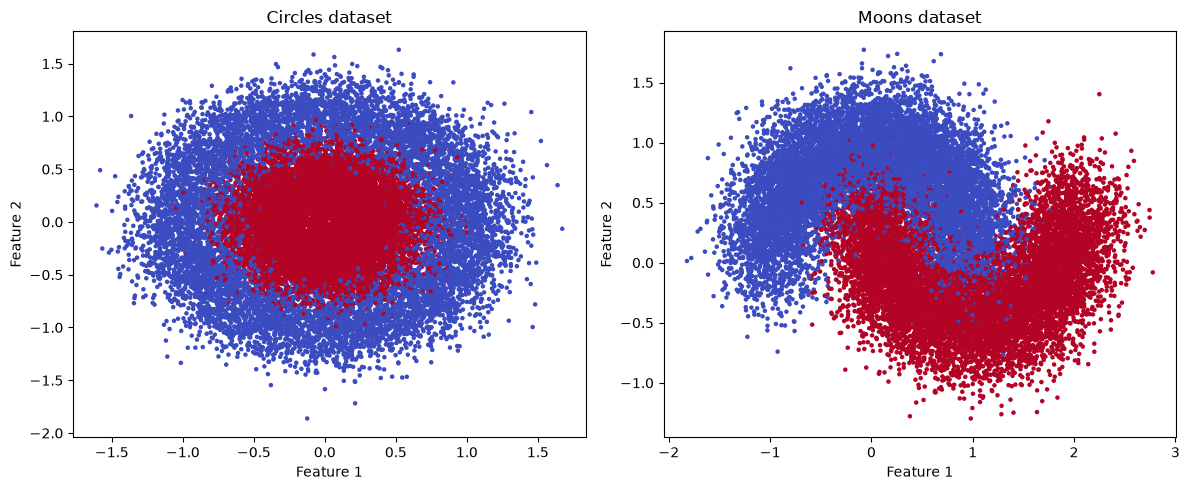

In [15]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons

N_SAMPLES = 20000
random_state = 42

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Generate and plot circles
X_circles, y_circles = make_circles(
    n_samples=N_SAMPLES,
    noise=0.2,
    factor=0.4,
    random_state=random_state
)

axes[0].scatter(
    X_circles[:, 0],
    X_circles[:, 1],
    c=y_circles,
    cmap="coolwarm",
    s=5
)
axes[0].set_title("Circles dataset")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# Generate and plot moons
X_moons, y_moons = make_moons(
    n_samples=N_SAMPLES,
    noise=0.25,
    random_state=random_state
)

axes[1].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="coolwarm",
    s=5
)
axes[1].set_title("Moons dataset")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

# Unified loader: 2D (circles/moons) vs cats

This function lets you flip with one flag between the small 2D dataset (like Part 1) and the cats/non-cats dataset, but returns data formatted for the training code.

In [16]:
def load_dataset_flexible(dataset="circles",
                          cats_train_path=None,
                          cats_test_path=None,
                          use_pca=False,
                          pca_dim=100,
                          random_state=0):
    """
    Flexible loader that returns (X_train, y_train, X_test, y_test)
    ready for the MLP + gradient framework.

    Shapes:
      X_train: (m_train, n_features)
      y_train: (m_train,)
      X_test:  (m_test,  n_features)
      y_test:  (m_test,)

    dataset:
      - "circles" or "moons": synthetic 2D datasets
      - "cats": uses H5-based cats vs non-cats dataset
    """
    if dataset in ["circles", "moons"]:
        N_SAMPLES = 20000
        TEST_SIZE = 0.2

        if dataset == "circles":
            X, y = make_circles(n_samples=N_SAMPLES, noise=0.2, factor=0.4, random_state=random_state)
        else:
            X, y = make_moons(n_samples=N_SAMPLES, noise=0.25, random_state=random_state)

        scaler = StandardScaler().fit(X)
        X_scaled = scaler.transform(X).astype(np.float32)
        y = y.astype(int)

        X_train, X_test, y_train, y_test = train_test_split(
            X_scaled, y, test_size=TEST_SIZE, random_state=random_state, stratify=y
        )

        print(f"[{dataset}] X_train: {X_train.shape}, X_test: {X_test.shape}")
        print(f"[{dataset}] Class balance train: {np.bincount(y_train)}, test: {np.bincount(y_test)}")

        return X_train, y_train, X_test, y_test

    elif dataset == "cats":
        assert cats_train_path is not None and cats_test_path is not None, \
            "Provide cats_train_path and cats_test_path for dataset='cats'."

        X_train_orig, y_train_orig, X_test_orig, y_test_orig = load_cats_h5(
            cats_train_path, cats_test_path
        )

        X_train, y_train, X_test, y_test = preprocess_cats_dataset(
            X_train_orig, y_train_orig,
            X_test_orig, y_test_orig,
            use_pca=use_pca,
            pca_dim=pca_dim,
            random_state=random_state,
        )

        return X_train, y_train, X_test, y_test

    else:
        raise ValueError(f"Unknown dataset: {dataset}. Choose 'circles', 'moons', or 'cats'.")


# To do:

In the following cells, functions to build a feed-forward DNN are provided.

Analyse these function and for each function complete the description.

In [28]:
def get_activation(name):
    """Return (activation_function, activation_derivative) for the given name.
    Supported activations:
        - tanh
        - sigmoid
        - relu
    """
    name = name.lower()

    if name == "tanh":
        def f(z):
            return np.tanh(z)
        def f_prime(z):
            return 1 - np.tanh(z)**2
        return f, f_prime

    elif name == "sigmoid":
        def f(z):
            # Numerically stable sigmoid via input clipping
            zc = np.clip(z, -40.0, 40.0)
            return 1.0 / (1.0 + np.exp(-zc))
        def f_prime(z):
            a = 1.0 / (1.0 + np.exp(-np.clip(z, -40.0, 40.0)))
            return a * (1.0 - a)
        return f, f_prime

    elif name == "relu":
        def f(z):
            # Numerically stable relu via input clipping
            zc = np.clip(z, -50.0, 50.0)
            return np.maximum(0, zc)
        def f_prime(z):
            return (z > 0).astype(float)
        return f, f_prime

    else:
        raise ValueError(f"Unsupported activation: {name}. Choose among 'tanh', 'sigmoid', 'relu'.")


def forward_propagation_deep(X, parameters, activation="tanh"):
    """Forward pass for an L-layer fully-connected network with sigmoid output.
    Args:
        X: input data of shape (n_x, m)
        parameters: dict of parameters {W1,b1,...,WL,bL}
        activation: hidden-layer activation name ("tanh", "sigmoid", or "relu")
    """
    f_hidden, _ = get_activation(activation)
    f_sigmoid, _ = get_activation("sigmoid")

    caches = {}
    A = X
    caches["A0"] = A

    # Keep a light reference to parameters in cache (fallback for backprop)
    caches["params"] = parameters

    L = len([k for k in parameters.keys() if k.startswith("W")])

    for l in range(1, L + 1):
        W = parameters[f"W{l}"]
        b = parameters[f"b{l}"]
        Z = W @ A + b
        caches[f"Z{l}"] = Z
        caches[f"W{l}"] = W
        caches[f"b{l}"] = b

        if l < L:
            A = f_hidden(Z)
        else:
            A = f_sigmoid(Z)
        caches[f"A{l}"] = A

    AL = A  # shape (1, m)
    return AL, caches


def backward_propagation_deep(AL, Y, caches, activation="tanh"):
    """Backward pass for an L-layer fully-connected network with sigmoid output.
    Args:
        AL: output of the forward pass
        Y: true labels
        caches: dict of intermediate values from the forward pass
        activation: hidden-layer activation name ("tanh", "sigmoid", or "relu")
    """
    if Y.ndim == 1:
        Y = Y.reshape(1, -1)
    m = Y.shape[1]

    # Number of layers
    L = len([k for k in caches.keys() if k.startswith("Z")])

    # Output layer gradient
    dZ = AL - Y

    grads = {f"dZ{L}": dZ}

    _, f_prime = get_activation(activation)

    for l in reversed(range(1, L + 1)):
        A_prev = caches[f"A{l-1}"]
        # Try to get W from caches; fallback to stored params
        W = caches.get(f"W{l}")
        if W is None:
            W = caches["params"][f"W{l}"]

        dW = (1.0 / m) * (dZ @ A_prev.T)
        db = (1.0 / m) * np.sum(dZ, axis=1, keepdims=True)

        grads[f"dW{l}"] = dW
        grads[f"db{l}"] = db

        if l > 1:
            dA_prev = W.T @ dZ
            Z_prev = caches[f"Z{l-1}"]
            dZ = dA_prev * f_prime(Z_prev)
            grads[f"dZ{l-1}"] = dZ

    return grads


def init_grad_history(parameters, track=("dZ", "dW", "db")):
    """Create an empty gradient history structure for all layers.

    Args:
        parameters: dict of parameters {W1,b1,...,WL,bL}
        track: tuple of gradient kinds to track (e.g., "dZ", "dW", "db")

    Returns:
        grad_hist: dict like { "dZ1": [], "dZ2": [], ..., "dWL": [] }
        where each entry will store a list of gradient summaries over iterations.
        
    """
    L = len([k for k in parameters.keys() if k.startswith("W")])
    grad_hist = {}
    for kind in track:
        grad_hist[kind] = {f"{kind}{l}": [] for l in range(1, L + 1)}
    return grad_hist


def update_grad_history(grad_hist, grads, metric="std"):
    """Append a summary statistic of each gradient to the history.

    Args:
        grad_hist: dict from init_grad_history
        grads: dict from backward_propagation_deep
        metric: one of {"std", "l2", "mean_abs", "max_abs"}

    Notes:
        - std: np.std(tensor)
        - l2:  np.linalg.norm(tensor) / sqrt(tensor.size)  (scale-invariant)
        - mean_abs: np.mean(np.abs(tensor))
        - max_abs:  np.max(np.abs(tensor))
    """
    def reduce_metric(arr):
        if metric == "std":
            return float(np.std(arr))
        if metric == "l2":
            return float(np.linalg.norm(arr) / np.sqrt(arr.size))
        if metric == "mean_abs":
            return float(np.mean(np.abs(arr)))
        if metric == "max_abs":
            return float(np.max(np.abs(arr)))
        raise ValueError("Unknown metric: " + str(metric))

    for kind, per_layer in grad_hist.items():
        for key in per_layer.keys():  # e.g., "dZ3", "dW2", "db1"
            if key in grads:
                val = reduce_metric(grads[key])
                per_layer[key].append(val)

def init_saturation_history(parameters):
    """
    Create empty saturation history for each layer.
    Returns:
        sat_hist: dict like { "A1": [], "A2": [], ..., "AL": [] }
        where each entry will store a list of saturation fractions over iterations.
    """
    L = len([k for k in parameters.keys() if k.startswith("W")])
    sat_hist = {f"A{l}": [] for l in range(1, L + 1)}
    return sat_hist


def _saturation_fraction(A, activation, tanh_thr=0.99, sig_eps=1e-2):
    """
    Compute the fraction of 'saturated' units in activation matrix A
    depending on the activation type.

    A: np.ndarray (n_l, m)
    activation: "tanh", "sigmoid", "relu"
    """
    activation = activation.lower()
    A_flat = A.reshape(-1)

    if activation == "tanh":
        sat = np.abs(A_flat) > tanh_thr
    elif activation == "sigmoid":
        sat = (A_flat < sig_eps) | (A_flat > 1.0 - sig_eps)
    elif activation == "relu":
        sat = (A_flat <= 0.0)  # dead ReLU
    else:
        raise ValueError(f"Unsupported activation for saturation: {activation}")

    if A_flat.size == 0:
        return 0.0
    return float(np.mean(sat))


def update_saturation_history(sat_hist, caches, activation):
    """
    Append current saturation fraction for each layer based on caches.

    sat_hist: dict from init_saturation_history
    caches:  dict from forward_propagation_deep containing A1, A2, ..., AL
    activation: hidden activation ("tanh", "sigmoid", "relu")

    Notes:
      - The last layer in your network uses sigmoid for the output.
        Here we typically care about saturation in *hidden* layers, so
        you can choose to:
          - use the same 'activation' for all layers (simpler),
          - or treat the last layer separately if you wish.
    """
    for key in sat_hist.keys():  # e.g., "A1", "A2", ...
        if key in caches:
            A = caches[key]
            frac = _saturation_fraction(A, activation=activation)
            sat_hist[key].append(frac)


def train_deep_model(
    X,
    Y,
    layer_dims,
    init_scheme="bad",
    hidden_activation="relu",
    learning_rate=0.01,
    num_iterations=3000,
    print_every=200,
    track_grad_kinds=("dZ", "dW"),
    metric="std",
    snapshot_every=None,
    track_saturation=True,
):
    """
    Train ...
    """
    # 1) Initialize parameters
    parameters = initialize_parameters_deep(
        layer_dims, scheme=init_scheme, activation=hidden_activation
    )
    initial_params = {k: v.copy() for k, v in parameters.items()}

    # 2) Trackers
    grad_hist = init_grad_history(parameters, track=track_grad_kinds)
    sat_hist = init_saturation_history(parameters) if track_saturation else None
    losses = []
    snapshots = []

    if Y.ndim == 1:
        Y = Y.reshape(1, -1)
    m = Y.shape[1]

    # 3) Training loop
    for it in range(num_iterations):
        # Forward
        AL, caches = forward_propagation_deep(X, parameters, activation=hidden_activation)

        # Binary cross-entropy loss (with clipping)
        eps = 1e-8
        ALc = np.clip(AL, eps, 1.0 - eps)
        loss = - (1.0 / m) * np.sum(Y * np.log(ALc) + (1 - Y) * np.log(1 - ALc))
        losses.append(float(loss))

        # Backward
        grads = backward_propagation_deep(AL, Y, caches, activation=hidden_activation)

        # Update params
        L = len([k for k in parameters if k.startswith("W")])
        for l in range(1, L + 1):
            parameters[f"W{l}"] -= learning_rate * grads[f"dW{l}"]
            parameters[f"b{l}"] -= learning_rate * grads[f"db{l}"]

        # Track gradient summaries
        update_grad_history(grad_hist, grads, metric=metric)

        # Track saturation summaries (per layer)
        if track_saturation:
            update_saturation_history(sat_hist, caches, activation=hidden_activation)

        # Optional snapshots for histograms
        if snapshot_every is not None and snapshot_every > 0 and (it % snapshot_every == 0 or it == num_iterations - 1):
            snap_caches = {k: v.copy() for k, v in caches.items() if k.startswith("A") or k.startswith("Z")}
            snap_grads = {k: v.copy() for k, v in grads.items() if k.startswith("dZ")}
            snapshots.append((it, snap_caches, snap_grads))

        if print_every and (it % print_every == 0 or it == num_iterations - 1):
            print(f"Iter {it:5d} | loss = {loss:.5f}")

    return parameters, losses, grad_hist, initial_params, snapshots, sat_hist


def _fan_in_out(n_prev, n_curr):
    """Utility: return (fan_in, fan_out)."""
    return n_prev, n_curr


def initialize_parameters_deep(layers_dims, scheme="bad", activation="tanh", seed=42):
    """Initialize parameters for an L-layer fully-connected network.

    Args:
        layers_dims: list of layer sizes [n0, n1, ..., nL] with nL == 1 for binary output
        scheme: one of {"bad", "xavier", "he"}
        activation: hidden-layer activation name ("tanh", "sigmoid", or "relu")
        seed: numpy RNG seed for reproducibility

    Returns:
        parameters: dict with keys {W1,b1,...,WL,bL}

    Notes:
        - "bad": deliberately poor init (Normal(0, 1.0)) to trigger saturation/vanishing with tanh/sigmoid
        - "xavier": Glorot uniform for tanh/sigmoid (limit = sqrt(6/(fan_in+fan_out)))
        - "he": Kaiming/He uniform for ReLU (limit = sqrt(6/fan_in))
        - Biases are initialized to zeros in all cases
    """
    np.random.seed(seed)
    L = len(layers_dims) - 1
    parameters = {}

    scheme = scheme.lower()
    activation = activation.lower()

    for l in range(1, L + 1):
        n_prev, n_curr = layers_dims[l-1], layers_dims[l]
        fan_in, fan_out = _fan_in_out(n_prev, n_curr)

        if scheme == "bad":
            # Large variance regardless of activation (to show failure with tanh/sigmoid)
            W = np.random.randn(n_curr, n_prev) * 2.0
        elif scheme == "xavier":
            # Recommended for tanh/sigmoid
            limit = np.sqrt(6.0 / (fan_in + fan_out))
            W = np.random.uniform(-limit, limit, size=(n_curr, n_prev))
        elif scheme == "he":
            # Recommended for ReLU
            limit = np.sqrt(6.0 / fan_in)
            W = np.random.uniform(-limit, limit, size=(n_curr, n_prev))
        else:
            raise ValueError("Unknown initialization scheme: " + scheme)

        b = np.zeros((n_curr, 1))
        parameters[f"W{l}"] = W
        parameters[f"b{l}"] = b

    return parameters


def predict(parameters, X, threshold=0.5, hidden_activation="tanh"):
    """Return binary predictions (0/1) using the current parameters and sigmoid head."""
    AL, _ = forward_propagation_deep(X, parameters, activation=hidden_activation)
    return (AL >= threshold).astype(int)


def accuracy(parameters, X, Y, hidden_activation="tanh", threshold=0.5):
    """Compute accuracy in [0,1]."""
    if Y.ndim == 1:
        Y = Y.reshape(1, -1)
    Y_pred = predict(parameters, X, threshold=threshold, hidden_activation=hidden_activation)
    return float(np.mean(Y_pred == Y))


# To do:

Analyse the following functions and for each function add a description.

In [18]:
def plot_saturation_evolution(sat_hist, activation="tanh"):
    """
    Plot saturation fraction per layer over training.

    sat_hist: dict like { "A1": [..], "A2": [..], ... }

    Interpretation:
      - tanh: Units are saturated if their output is close to ±1.
      - sigmoid: Units are saturated if their output is close to 0 or 1.
      - relu: Units are dead if their output is 0.
    """
    plt.figure(figsize=(8, 5))
    for key, series in sat_hist.items():
        if len(series) > 0:
            plt.plot(series, label=key)
    plt.xlabel("Iteration")
    plt.ylabel("Saturation fraction")
    plt.title(f"Saturation evolution per layer ({activation})")
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_weights_evolution(initial_params, trained_params, activation="relu"):
    """
    Compare initial vs final weight distributions for each layer.

    Args:
        initial_params: dict {W1, b1, ..., WL, bL} BEFORE training
        trained_params: dict {W1, b1, ..., WL, bL} AFTER training
        activation: activation name (used only for plot titles)

    Behavior:
        - One subplot per layer (W1, W2, ..., WL)
        - Shows histograms (initial vs final) to visualize
          shrinkage, explosion, or stabilization of weights.
    """

    # Get only weight keys ("W1", "W2", ...)
    weight_keys = [k for k in trained_params.keys() if k.startswith("W")]
    n_layers = len(weight_keys)

    # Layout: 3 columns, enough rows
    cols = 3
    rows = int(np.ceil(n_layers / cols))

    plt.figure(figsize=(5 * cols, 3.5 * rows))

    for i, key in enumerate(weight_keys, start=1):
        w_init = initial_params[key].flatten()
        w_final = trained_params[key].flatten()

        plt.subplot(rows, cols, i)
        plt.hist(w_init, 50, alpha=0.5, label="initial")
        plt.hist(w_final, 50, alpha=0.5, label="final")
        plt.title(f"{key} — {activation}")
        plt.xlabel("Weight value")
        plt.ylabel("Frequency")
        plt.legend()

    plt.suptitle(f"Weight distributions evolution ({activation})", fontsize=14)
    plt.tight_layout()
    plt.show()

def plot_gradients_evolution(grad_hist, activation="relu", metric="std", logy=True):
    """Plot gradient evolution per layer over iterations.

    Args:
        grad_hist: gradient history produced by init_grad_history/update_grad_history
        activation: name used only for figure titles/labels
        metric: same metric that was used to build the history (for labeling)
        logy: if True, use a log scale on the y-axis (helpful to reveal vanishing)

    Behavior:
        - One figure per tracked gradient kind (dZ, dW, db)
        - Each layer is a separate line in the figure
    """
    for kind, per_layer in grad_hist.items():
        plt.figure(figsize=(8, 5))
        for key, series in per_layer.items():
            if len(series) > 0:
                plt.plot(series, label=key)
        if logy:
            plt.yscale("log")
        plt.xlabel("Iteration")
        plt.ylabel(f"{kind} — {metric}")
        plt.title(f"Gradient evolution ({kind}) — {activation}")
        plt.legend(loc="best", fontsize=9, ncol=2)
        plt.tight_layout()
        plt.show()


# Task #1: Let's go through all the steps with one activation function, one initialization method and one dataset.

Activation function = Tanh

Initialization method = Bad

Dataset : circles

## T1.1: Load & preprocess the "circles" dataset

In [19]:
# Choose dataset
DATASET = "circles"   # or "cats" or "moons"

USE_PCA = True     # True = faster training, clearer gradients
PCA_DIM = 100

if DATASET == "cats":
    X_train, y_train, X_test, y_test = load_dataset_flexible(
        dataset="cats",
        cats_train_path="data/train_catvnoncat.h5",
        cats_test_path="data/test_catvnoncat.h5",
        use_pca=USE_PCA,
        pca_dim=PCA_DIM,
    )
else:
    X_train, y_train, X_test, y_test = load_dataset_flexible(dataset=DATASET)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

[circles] X_train: (16000, 2), X_test: (4000, 2)
[circles] Class balance train: [8000 8000], test: [2000 2000]
X_train: (16000, 2) X_test: (4000, 2)


## T1.2: Define architecture 

In [20]:
# last = 1 for binary classification (sigmoid)

n_x = X_train.shape[1]
layer_dims = [n_x, 64, 64, 64, 1]  # Should be deep enough to show vanishing...

print("Architecture:", layer_dims)

Architecture: [2, 64, 64, 64, 1]


## T1.3: Train the model

In [21]:
HIDDEN_ACT = "tanh"    
INIT_SCHEME = "bad"    

parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(X_train.T,y_train,layer_dims,INIT_SCHEME,HIDDEN_ACT )


Iter     0 | loss = 7.02434
Iter   200 | loss = 0.49351
Iter   400 | loss = 0.35066
Iter   600 | loss = 0.30133
Iter   800 | loss = 0.27980
Iter  1000 | loss = 0.26702
Iter  1200 | loss = 0.25772
Iter  1400 | loss = 0.25030
Iter  1600 | loss = 0.24434
Iter  1800 | loss = 0.23895
Iter  2000 | loss = 0.23403
Iter  2200 | loss = 0.22980
Iter  2400 | loss = 0.22630
Iter  2600 | loss = 0.22316
Iter  2800 | loss = 0.22033
Iter  2999 | loss = 0.21789


## T1.4: Plot gradient evolution

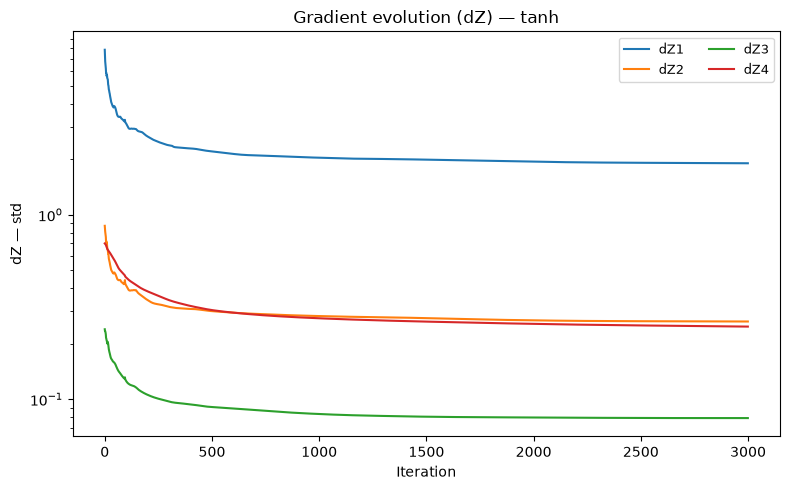

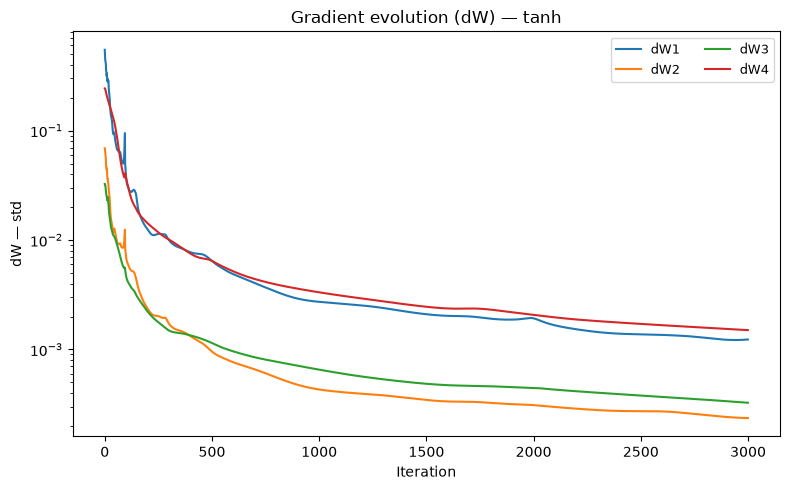

In [22]:
plot_gradients_evolution(grad_hist, activation=HIDDEN_ACT, metric="std", logy=True)

## T1.5: Plot saturation evolution

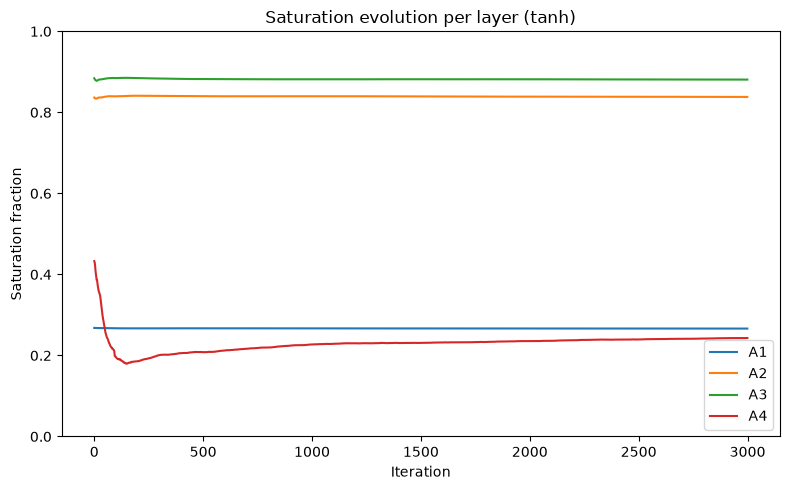

In [23]:
plot_saturation_evolution(sat_hist, activation=HIDDEN_ACT)

## T1.6: Plot weight distribution

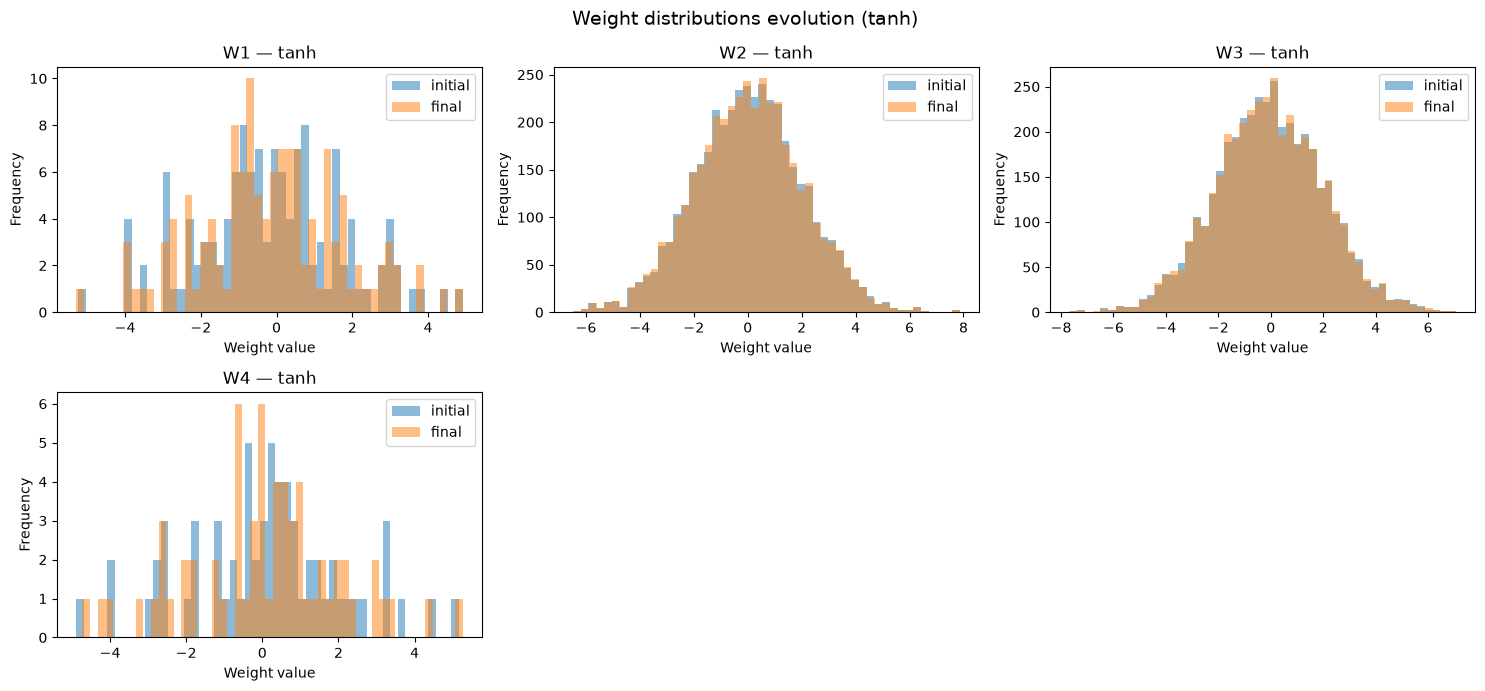

In [24]:
plot_weights_evolution(initial_params, parameters, activation=HIDDEN_ACT)

### Your analysis here:

**Why standard deviation (std) represents gradient magnitude:**
- Because the dataset, initial weights, and activation function ($\tanh$) are zero-centered and symmetric, the average gradient across any layer is approximately zero ($\mu \approx 0$).
- When $\mu \approx 0$, the standard deviation simplifies to the Root Mean Square (RMS) magnitude: $\text{std}(g) \approx \sqrt{\frac{1}{N}\sum g_i^2}$. Therefore, $\text{std}$ directly measures the typical scale and strength of the gradients in each layer.

**Pre-activation (dZ) gradient evolution:**
- **Across iterations:** Gradients naturally decrease over training iterations as the model converges and loss decreases (this is standard convergence, not vanishing gradient).
- **Across layers (depth):** $dZ$ does not decrease smoothly layer-by-layer backwards. Instead:
  - $dZ_3$ drops sharply compared to $dZ_4$ because the activation derivative $\tanh'(Z_3)$ collapses toward 0, and $W_4$ (having only 1 unit) provides no dimension-based amplification.
  - $dZ_2$ and $dZ_1$ bounce back up to much higher magnitudes because backpropagating through large weight matrices ($64 \times 64$ with $\text{std} = 2.0$) artificially multiplies the backward signal by $(W^{[l]})^T$, introducing an amplification factor of roughly $\sqrt{64} \times 2 = 16\times$.
  - This shows an unstable clash between activation derivative shrinkage and artificial matrix amplification.

**(dW) gradient evolution:**
- Weight gradients reflect the actual parameter updates ($\Delta W = -\alpha \cdot dW$) and reveal the true vanishing gradient problem:
  - Rather than a textbook monotonic decrease ($dW_4 > dW_3 > dW_2 > dW_1$), we observe an internal "dead zone": $dW_2$ and $dW_3$ in the intermediate layers collapse to extremely small magnitudes ($\approx 10^{-4}$), more than an order of magnitude smaller than the outer layers.
  - **Why $dW_1$ is larger than $dW_2$ (instead of smaller):**
    - By definition, $dW^{[l]} = \frac{1}{m} dZ^{[l]} (A^{[l-1]})^T$, so $dW$ directly scales with the pre-activation gradient $dZ$.
    - $dW_1$ inherits the high magnitude of $dZ_1$, which was boosted by the $16\times$ matrix amplification from $W_2^T$ and maintained because Layer 1 connects to only 2 input features (keeping its pre-activations smaller and its derivative $\tanh'(Z_1)$ active).
    - In contrast, $dW_2$ and $dW_3$ are starved because the derivative terms in the deeper 64-unit layers collapsed.
  - Because intermediate updates are negligible, the middle layers are practically frozen and fail to learn.
  - Only the boundary layers ($dW_1$ and $dW_4$) receive noticeable updates, meaning the deep network fails to train internal representations end-to-end.

**Saturation evolution:**
- **Definition:** A $\tanh$ neuron is considered saturated when $|A| > 0.99$, meaning its pre-activation $|Z|$ is so large that the neuron operates in its flat asymptotic tails where the derivative $\tanh'(Z) = 1 - \tanh^2(Z) \approx 0$.
- **Deep layers are severely saturated:**
  - Layers $A_2$ and $A_3$ immediately suffer from massive saturation (~84% and ~88% of neurons respectively). Because each neuron sums 64 inputs weighted by large values ($\sigma_W = 2.0$), the pre-activations $Z$ explode, pushing almost 9 out of 10 neurons into the zero-gradient region.
- **Layer $A_1$ is largely spared:**
  - Layer $A_1$ shows much lower saturation (~27%) because it receives only 2 input features ($n_0 = 2$). Summing only 2 terms prevents $Z_1$ from blowing up, keeping over 70% of its neurons in the active, linear regime.
- **The "Vicious Cycle" (Flat lines over iterations):**
  - The saturation fraction remains completely flat across all 3,000 iterations.
  - This illustrates a self-reinforcing deadlock: high saturation kills gradients ($dW \approx 0$), zero gradients mean weights never change, and unchanging weights mean neurons can never escape saturation. The middle layers are permanently locked.

**Weight distribution evolution:**
- The initial weights for all layers show an excessively wide dispersion (spanning $[-6, +6]$) due to the "bad" initialization scheme ($W \sim \mathcal{N}(0, 2^2)$).
- For the intermediate layers $W_2$ and $W_3$, the initial and final histograms are virtually identical and perfectly superimposed. This proves that no learning took place in these layers—their parameters remained completely frozen throughout all 3,000 iterations.
- Minor updates are visible only in $W_4$ and $W_1$, confirming that poor initialization prevents end-to-end parameter optimization across the deep architecture.

# **Task #2**

The purpose of the following exercises is to help you **experiment**, **observe**, and **understand** how initialization and activation functions influence the learning dynamics of deep neural networks.

You have nothing to code — the framework is fully provided.
Your task is to **run experiments**, **interpret plots**, and **answer analysis questions**.

## **Exercise 1: Observing vanishing gradients on a 2D dataset**

### **Objective:**

Understand how **bad initialization** causes **activation saturation** and **vanishing gradients**, even on simple datasets.

### Instructions

1. Set dataset to `"circles"` or `"moons"`.
2. Use a deep architecture (e.g. `[2, 64, 64, 64, 64, 1]`).
3. Train with:

   * `hidden_activation="tanh"`
   * `init_scheme="bad"`
    
4. Plot:

   * `plot_gradients_evolution(...)`
   * `plot_saturation_evolution(...)`
   * `plot_weights_evolution(...)`

### **What to observe**

* Gradients shrinking layer by layer
* Activation saturation in middle/late layers
* Weight collapse during training

### **Questions**

1. Which layers are the first to vanish? Why?
2. What does the saturation curve tell you about tanh behavior?
3. Why does “bad initialization” make training impossible?

[circles] X_train: (16000, 2), X_test: (4000, 2)
[circles] Class balance train: [8000 8000], test: [2000 2000]
Iter     0 | loss = 5.12555
Iter   200 | loss = 0.77906
Iter   400 | loss = 0.54291
Iter   600 | loss = 0.44548
Iter   800 | loss = 0.39395
Iter  1000 | loss = 0.35833
Iter  1200 | loss = 0.33051
Iter  1400 | loss = 0.31182
Iter  1600 | loss = 0.29666
Iter  1800 | loss = 0.28324
Iter  2000 | loss = 0.27152
Iter  2200 | loss = 0.26348
Iter  2400 | loss = 0.25669
Iter  2600 | loss = 0.25112
Iter  2800 | loss = 0.24680
Iter  2999 | loss = 0.24303


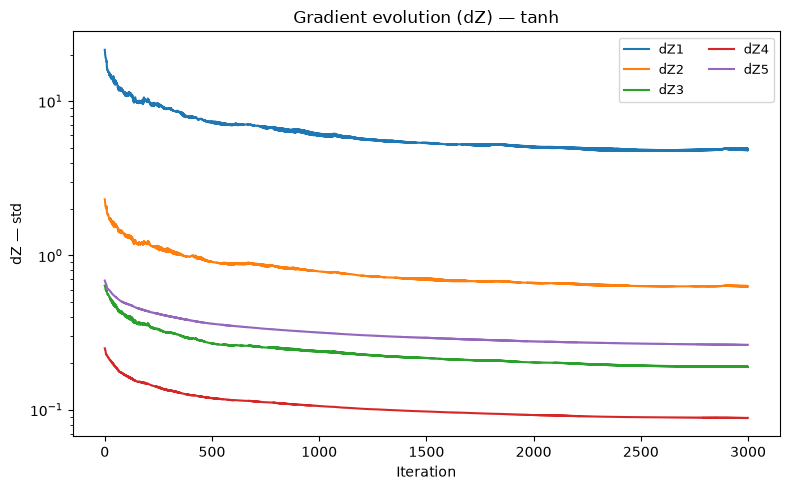

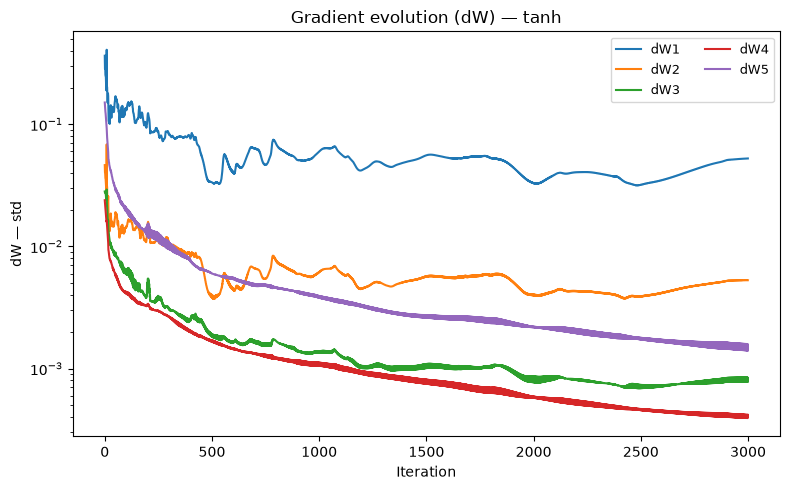

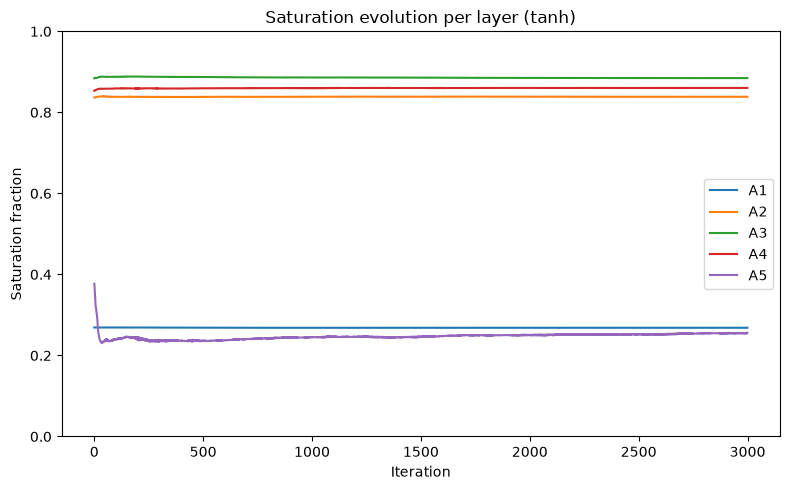

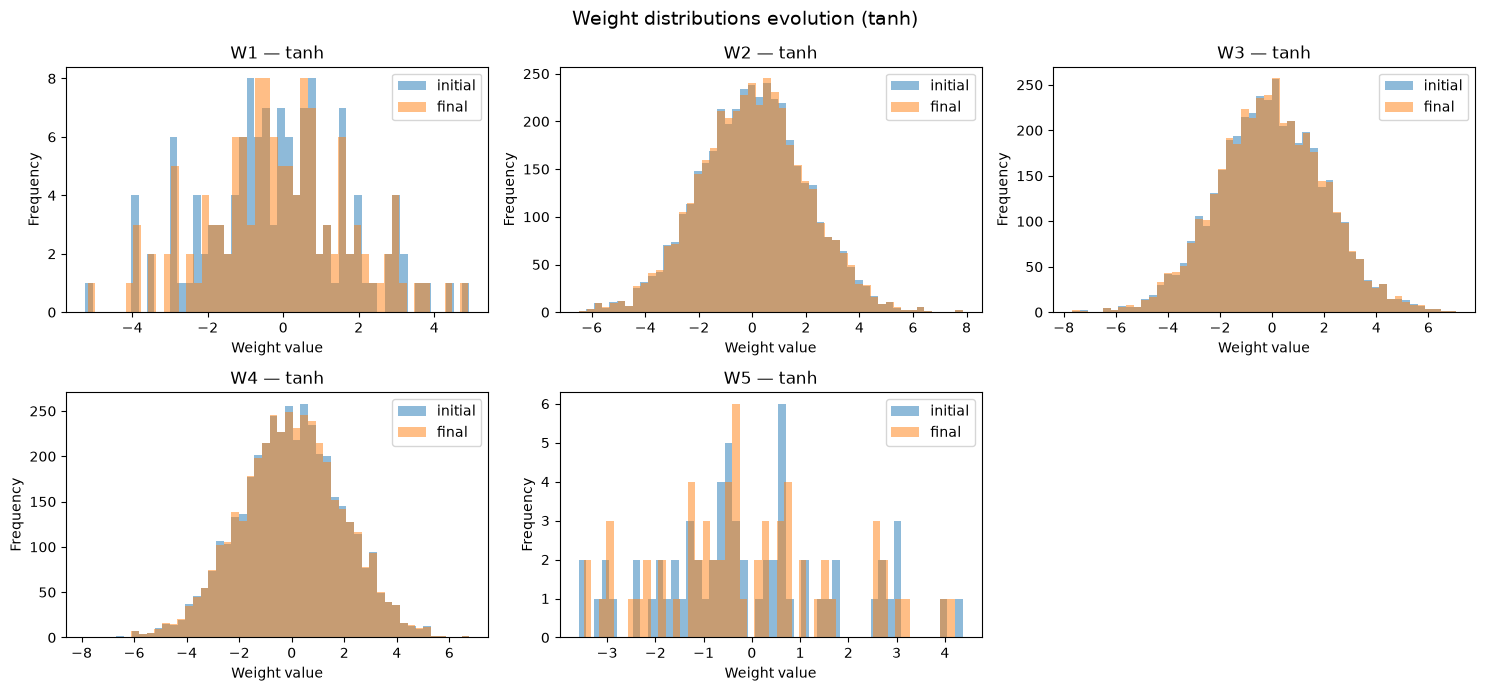

In [25]:
# Exercise 1: vanishing gradients with tanh and bad initialization
DATASET = "circles"  # Change to "moons" to repeat the experiment.
X_train, y_train, X_test, y_test = load_dataset_flexible(
    dataset=DATASET,
    random_state=42,
)

layer_dims = [X_train.shape[1], 64, 64, 64, 64, 1]
HIDDEN_ACT = "tanh"
INIT_SCHEME = "bad"

parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(
    X_train.T,
    y_train,
    layer_dims=layer_dims,
    init_scheme=INIT_SCHEME,
    hidden_activation=HIDDEN_ACT,
    learning_rate=0.01,
    num_iterations=3000,
    print_every=200,
    snapshot_every=200,
    track_saturation=True,
)

plot_gradients_evolution(grad_hist, activation=HIDDEN_ACT, metric="std", logy=True)
plot_saturation_evolution(sat_hist, activation=HIDDEN_ACT)
plot_weights_evolution(initial_params, parameters, activation=HIDDEN_ACT)


### Answers

1. **The deeper layers vanish first**, which is contrary to the usual textbook vanishing gradient pattern where earlier layers vanish most. 

    This happens because during backpropagation, there are **two opposing forces** multiplying each other:
* **The tanh derivative:** This is the element responsible for the vanishing gradient. Because of the large initial weights, the preactivations ($Z$) blow up, pushing neurons into saturation where the tanh derivative is extremely small ($\tanh'(Z) \approx 0$).
* **The weight matrices:** The weights are initialized with high variance and relatively large values. Multiplying by these large weight matrices during backpropagation counteracts and reverses the vanishing effect as the signal travels further backward.
                                                                                                                                                                         * **Layer 5 is an exception** to this vanishing behavior because it is the output layer with only a single neuron, whose gradient is computed directly from the loss ($dZ_5 = A_5 - Y$) rather than passing through saturated hidden layers.


2. It shows that when inputs are large, $\tanh$ squashes them toward its bounds ($-1$ and $+1$), where the function completely flattens out. In these saturated regions, its derivative drops to near zero ($\tanh'(z) \approx 0$), making the neuron insensitive to changes and unable to pass gradients backward.

3. Bad initialization pushes activations into saturated regimes and makes gradients collapse layer by layer. The resulting weight updates are too small to move neurons back into the sensitive, approximately linear part of tanh, so the loss changes very slowly and the network effectively cannot learn the decision boundary.


## **Exercise 2: Fixing vanishing gradients with Xavier initialization**

### **Objective:**

Show empirically that **Xavier initialization** stabilizes tanh networks.

### Instructions

Repeat Exercise 1 but with:

* `init_scheme="xavier"`

### What to observe

* Gradients remain stable
* Saturation greatly reduced
* Training loss decreases properly

### **Questions**

1. Compare gradient curves between bad and Xavier. What changed?
2. Explain why Xavier’s variance formula solves the tanh saturation problem.
3. Does training become faster? Why?

[circles] X_train: (16000, 2), X_test: (4000, 2)
[circles] Class balance train: [8000 8000], test: [2000 2000]
Iter     0 | loss = 0.69723
Iter   200 | loss = 0.68522
Iter   400 | loss = 0.67573
Iter   600 | loss = 0.65999
Iter   800 | loss = 0.63194
Iter  1000 | loss = 0.58414
Iter  1200 | loss = 0.51409
Iter  1400 | loss = 0.42979
Iter  1600 | loss = 0.34941
Iter  1800 | loss = 0.28772
Iter  2000 | loss = 0.24616
Iter  2200 | loss = 0.21982
Iter  2400 | loss = 0.20345
Iter  2600 | loss = 0.19324
Iter  2800 | loss = 0.18679
Iter  2999 | loss = 0.18266


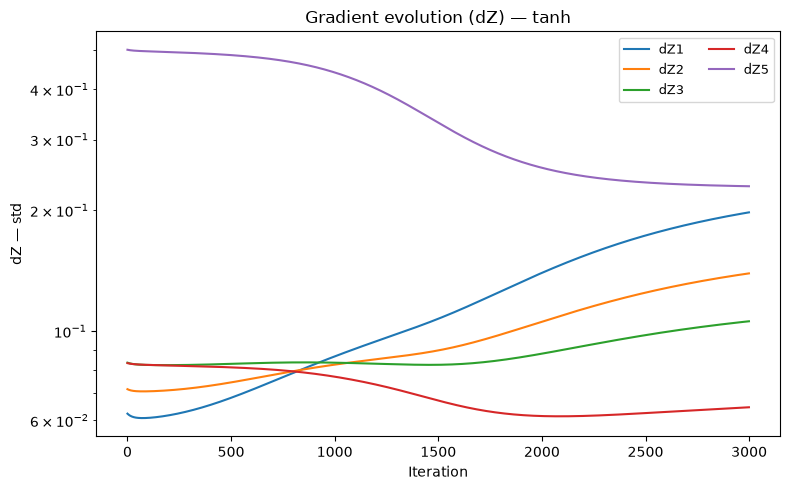

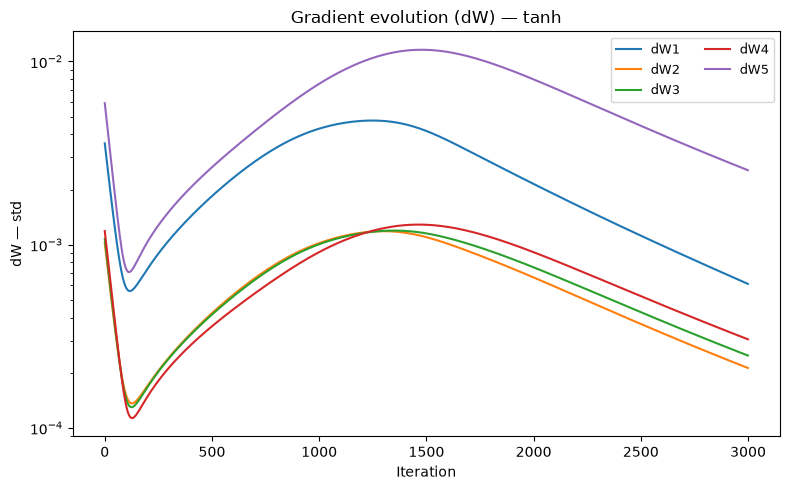

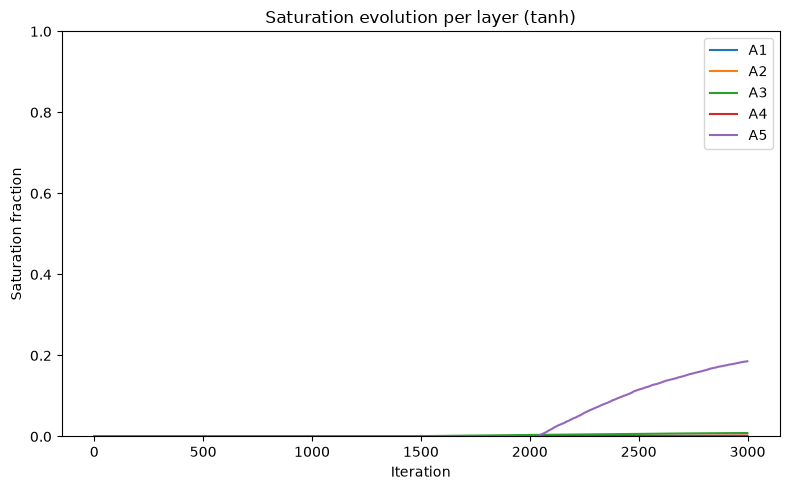

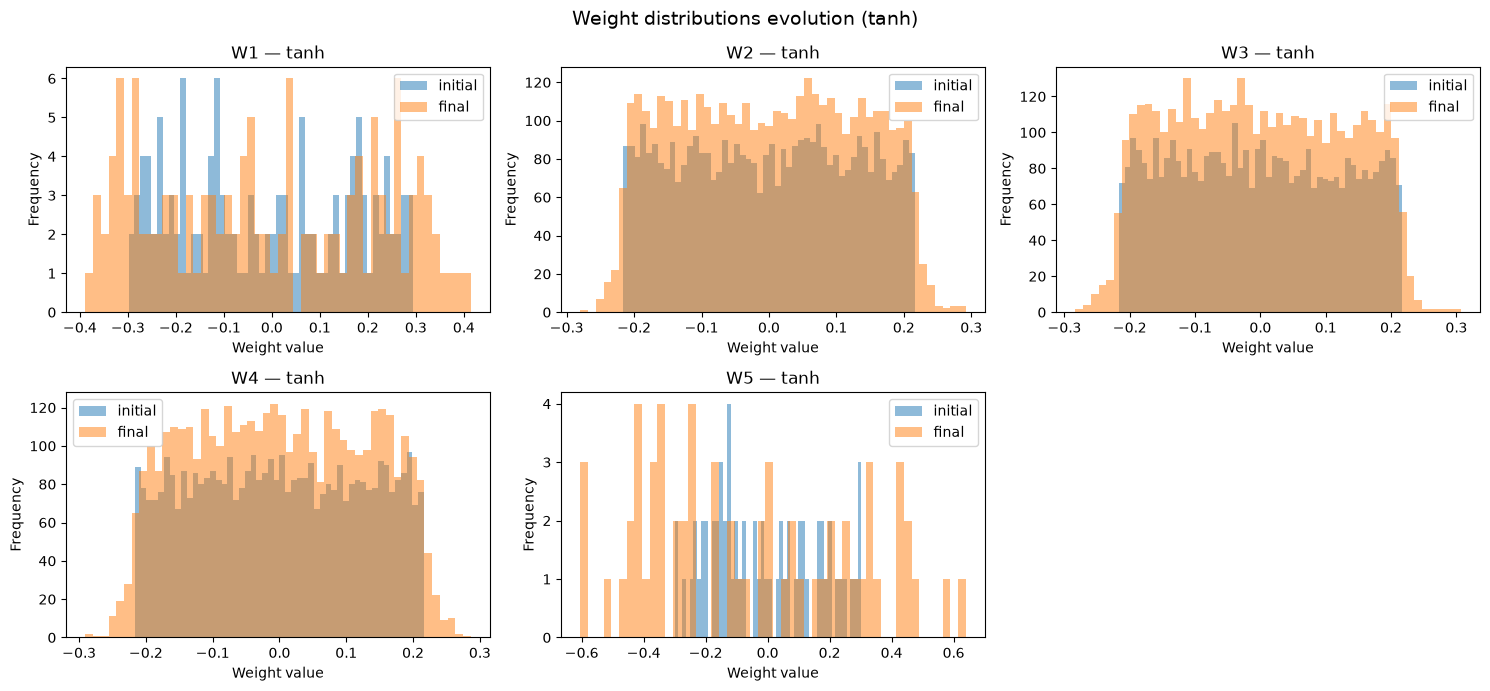

In [26]:
# Exercise 2: Xavier initialization with the same tanh network
DATASET = "circles"  # Use the same dataset as Exercise 1 for a fair comparison.
X_train, y_train, X_test, y_test = load_dataset_flexible(
    dataset=DATASET,
    random_state=42,
)

layer_dims = [X_train.shape[1], 64, 64, 64, 64, 1]
HIDDEN_ACT = "tanh"
INIT_SCHEME = "xavier"

parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(
    X_train.T,
    y_train,
    layer_dims=layer_dims,
    init_scheme=INIT_SCHEME,
    hidden_activation=HIDDEN_ACT,
    learning_rate=0.01,
    num_iterations=3000,
    print_every=200,
    snapshot_every=200,
    track_saturation=True,
)

plot_gradients_evolution(grad_hist, activation=HIDDEN_ACT, metric="std", logy=True)
plot_saturation_evolution(sat_hist, activation=HIDDEN_ACT)
plot_weights_evolution(initial_params, parameters, activation=HIDDEN_ACT)


### Answers

1. **With Xavier, the gradient curves changed in three key ways:**

   * **No vanishing across depth:** Under bad initialization, intermediate gradients ($dW_2, dW_3, dW_4$) collapsed to negligible values ($\approx 10^{-4}$), creating a large gap between layers. With Xavier, gradients across all layers stay at a healthy, usable scale ($\approx 10^{-2}$ to $10^{-1}$).
   * **Tightly grouped curves:** The curves for all layers are closely bundled together rather than widely scattered, proving that the learning signal passes through each layer without decaying.
   * **Smooth learning dynamics:** Instead of flatlining into frozen states, the curves decrease or increase gradually and smoothly over iterations, reflecting normal training process with parameters learning.

2. Xavier initialization keeps the weight variance approximately proportional to `2 / (fan_in + fan_out)`. This tunes the weights according to each layer num of neuron so it does not allow the weights to explode pre activation, therefor it preserves the scale of activations and backpropagated gradients through a tanh network, reducing the probability that pre-activations enter the saturated regions of tanh.

3. Yes. Training becomes faster because more neurons stay in tanh's sensitive region, so their derivatives remain non-negligible. Consequently, updates are bigger and reach earlier layers and the loss can decrease instead of being limited by vanishing gradients.

## **Exercise 3: Dead ReLU phenomenon with bad initialization**

### **Objective:**

Understand how large-variance initialization kills ReLU neurons.

### Instructions

1. Set dataset to `"circles"` or `"moons"`.
2. Use:

   * `hidden_activation="relu"`
   * `init_scheme="bad"`
3. Plot saturation (dead ReLUs = A=0).
4. Plot gradient evolution.

### What to observe

* Many neurons output exactly **0**
* Dead ReLUs become permanent
* Gradients drop to zero in deeper layers

### **Questions**

1. How does the saturation curve reveal dead ReLUs?
2. Why do gradients collapse faster with ReLU than with tanh?
3. What happens to the weight histograms?

[circles] X_train: (16000, 2), X_test: (4000, 2)
[circles] Class balance train: [8000 8000], test: [2000 2000]
Iter     0 | loss = 8.45651
Iter   200 | loss = 1.70632
Iter   400 | loss = 1.03963
Iter   600 | loss = 0.57512
Iter   800 | loss = 0.87908
Iter  1000 | loss = 0.52117
Iter  1200 | loss = 0.66617
Iter  1400 | loss = 0.71459
Iter  1600 | loss = 0.53523
Iter  1800 | loss = 0.49947
Iter  2000 | loss = 0.54675
Iter  2200 | loss = 0.66032
Iter  2400 | loss = 0.82655
Iter  2600 | loss = 0.68145
Iter  2800 | loss = 0.40118
Iter  2999 | loss = 0.57264


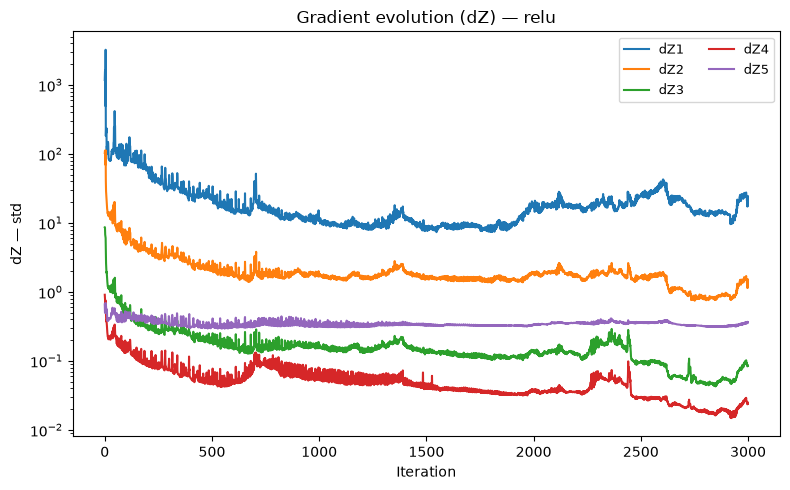

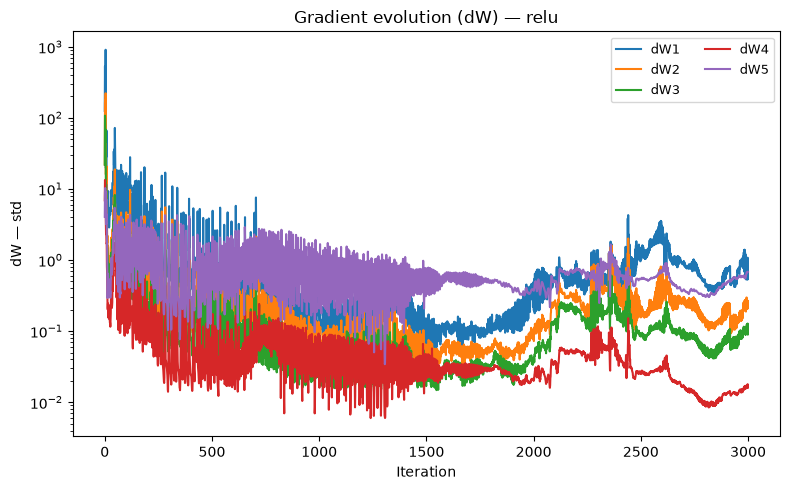

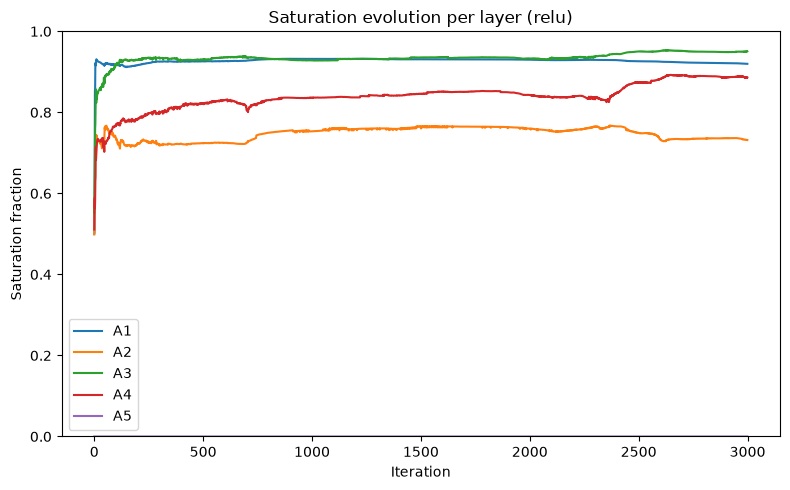

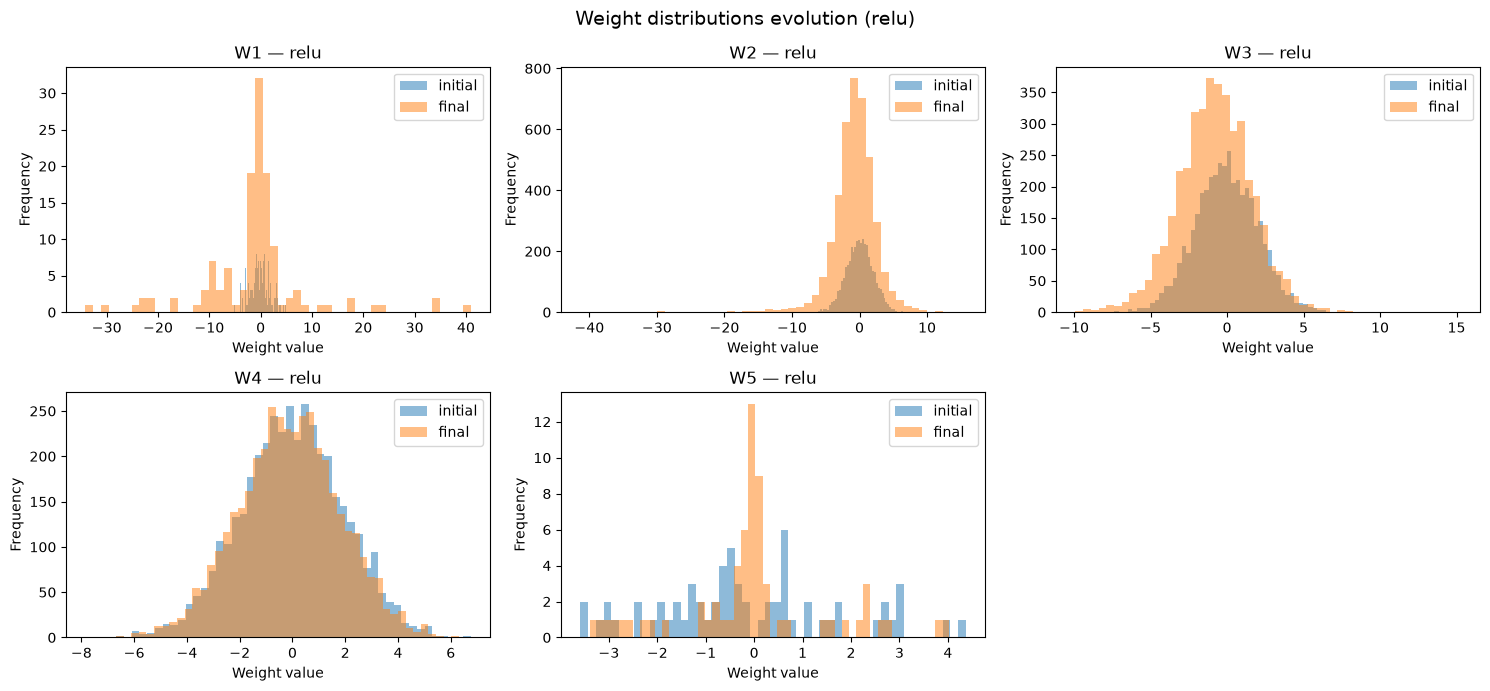

In [29]:
# Exercise 3: Dead ReLU phenomenon with bad initialization
DATASET = "circles"  # Set dataset to "circles" or "moons"
X_train, y_train, X_test, y_test = load_dataset_flexible(
    dataset=DATASET,
    random_state=42,
)

layer_dims = [X_train.shape[1], 64, 64, 64, 64, 1]
HIDDEN_ACT = "relu"
INIT_SCHEME = "bad"

parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(
    X_train.T,
    y_train,
    layer_dims=layer_dims,
    init_scheme=INIT_SCHEME,
    hidden_activation=HIDDEN_ACT,
    learning_rate=0.01,
    num_iterations=3000,
    print_every=200,
    snapshot_every=200,
    track_saturation=True,
)

plot_gradients_evolution(grad_hist, activation=HIDDEN_ACT, metric="std", logy=True)
plot_saturation_evolution(sat_hist, activation=HIDDEN_ACT)
plot_weights_evolution(initial_params, parameters, activation=HIDDEN_ACT)

### Answers

1. The saturation plot shows dead ReLUs through the steep vertical jump at the beginning of training. The moment a ReLU dies, saturation increases—and because all neurons with negative pre-activations die at once, saturation spikes immediately.
                
2. In tanh, gradients vanish gradually through repeated multiplications by small numbers. In contrast, ReLU kills gradients instantly: the moment a pre-activation is negative, the gradient becomes 0 immediately.

3. **What happens to the weight histograms:**

   * **Deep layer ($W_4$) remains frozen:** The initial and final histograms for $W_4$ are nearly identical, showing that it barely moved because the gradient reaching the deepest hidden layer collapsed.
   * **Earlier layers ($W_1, W_2, W_3$) disperse wildly:** The surviving non-dead neurons receive large, unstable gradients. This causes their weights to drift aggressively into extreme values (e.g., stretching out to $\pm 40$ in $W_1$ and $W_2$), which spreads the final histogram thinly across a much wider range and lowers its central peak.
   * **Key takeaway:** The histograms reveal severe instability: rather than training smoothly together, deeper hidden layers are frozen while earlier layers suffer from uncontrolled weight expansion.

## **Exercise 4: Fix dead ReLUs with He initialization**

### **Objective:**

Show that He initialization preserves gradient flow in ReLU networks.

### Instructions

Repeat Exercise 3 but with:

* `init_scheme="he"`

### What to observe

* Almost no dead ReLUs
* Gradient curves stay active
* Loss decreases smoothly

### **Questions**

1. Compare the saturation curves between bad init and He.
2. What property of He initialization preserves gradient variance?
3. Does weight evolution look more stable?

[circles] X_train: (16000, 2), X_test: (4000, 2)
[circles] Class balance train: [8000 8000], test: [2000 2000]
Iter     0 | loss = 0.67435
Iter   200 | loss = 0.50927
Iter   400 | loss = 0.39214
Iter   600 | loss = 0.28544
Iter   800 | loss = 0.22140
Iter  1000 | loss = 0.19266
Iter  1200 | loss = 0.18164
Iter  1400 | loss = 0.17678
Iter  1600 | loss = 0.17451
Iter  1800 | loss = 0.17338
Iter  2000 | loss = 0.17277
Iter  2200 | loss = 0.17244
Iter  2400 | loss = 0.17224
Iter  2600 | loss = 0.17210
Iter  2800 | loss = 0.17199
Iter  2999 | loss = 0.17192


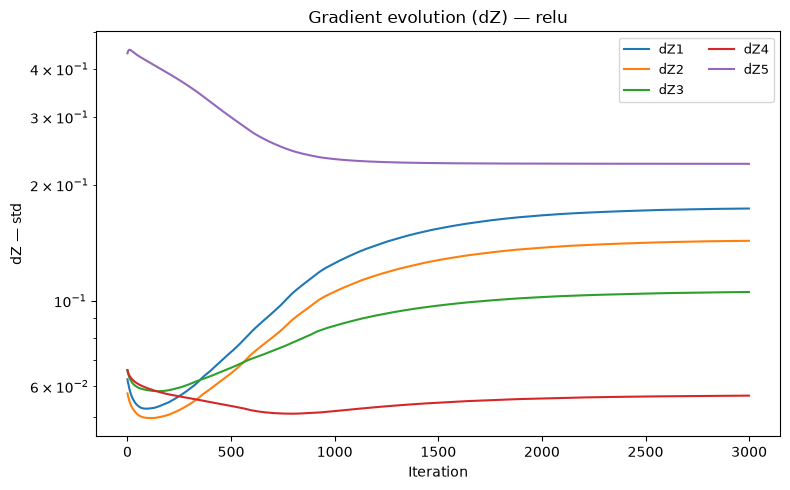

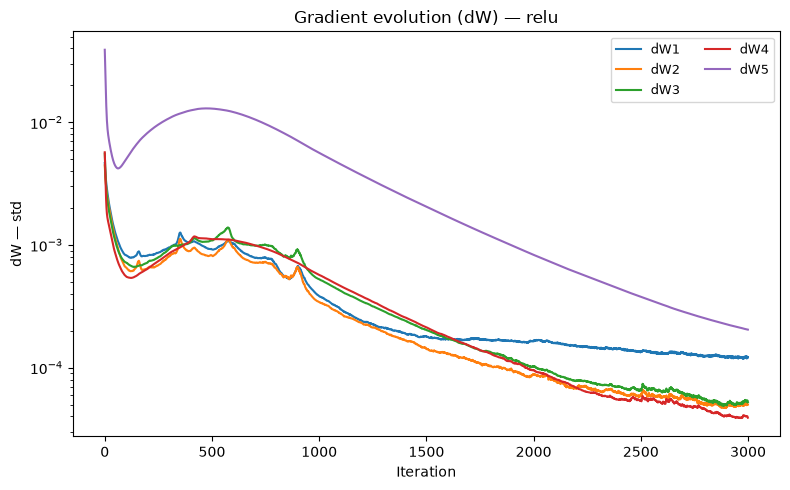

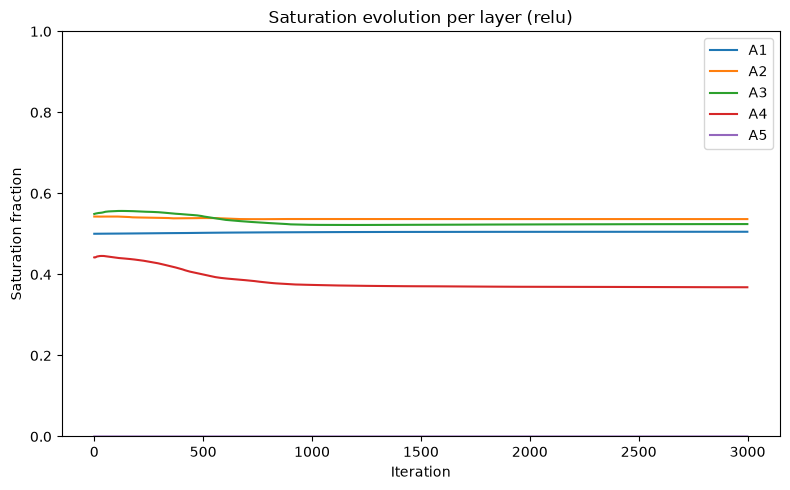

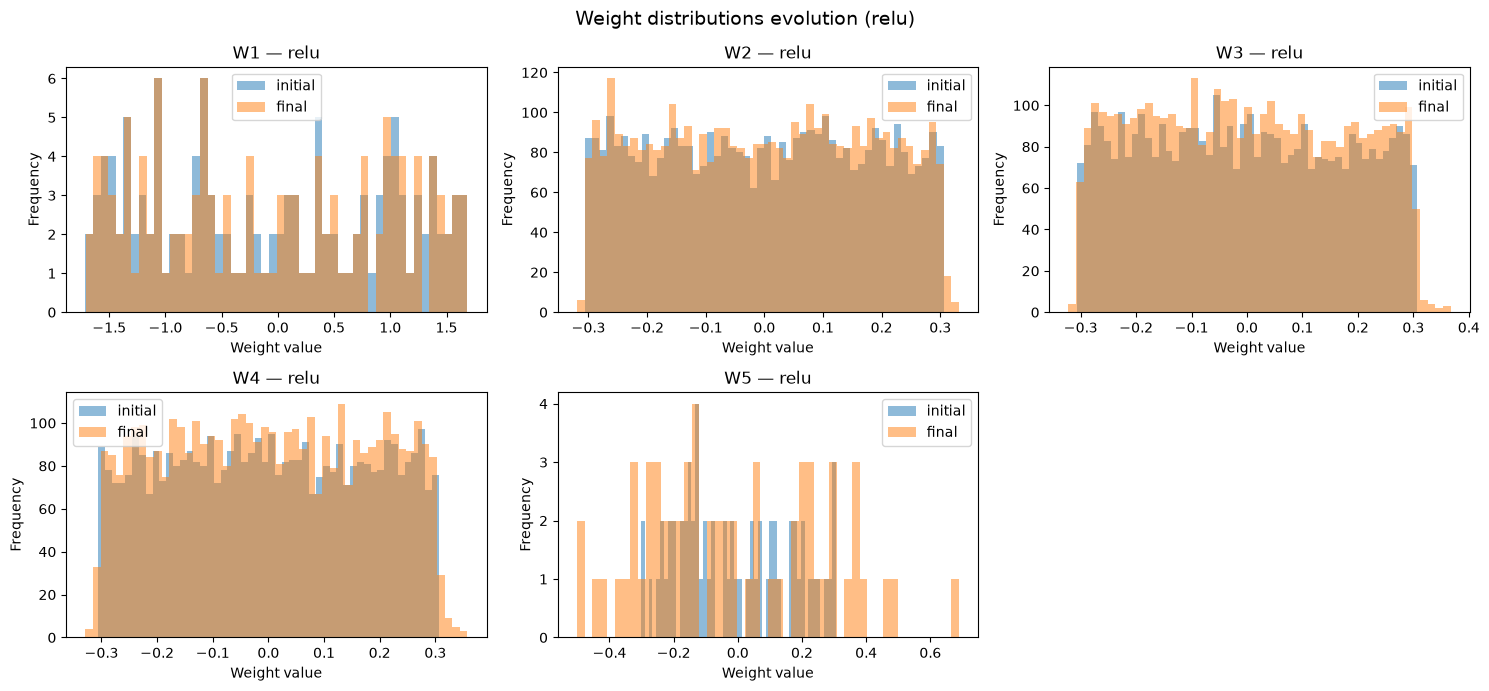

In [30]:
# Exercise 4: Fix dead ReLUs with He initialization
DATASET = "circles"  # Use the same dataset for a fair comparison
X_train, y_train, X_test, y_test = load_dataset_flexible(
    dataset=DATASET,
    random_state=42,
)

layer_dims = [X_train.shape[1], 64, 64, 64, 64, 1]
HIDDEN_ACT = "relu"
INIT_SCHEME = "he"

parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(
    X_train.T,
    y_train,
    layer_dims=layer_dims,
    init_scheme=INIT_SCHEME,
    hidden_activation=HIDDEN_ACT,
    learning_rate=0.01,
    num_iterations=3000,
    print_every=200,
    snapshot_every=200,
    track_saturation=True,
)

plot_gradients_evolution(grad_hist, activation=HIDDEN_ACT, metric="std", logy=True)
plot_saturation_evolution(sat_hist, activation=HIDDEN_ACT)
plot_weights_evolution(initial_params, parameters, activation=HIDDEN_ACT)

### Answers

1. With He initialization, the saturation curve stays stable throughout all iterations, completely avoiding the sudden initial spike of neurons dying and entering saturation seen with bad initialization.

2. He initialization sets the weight variance to `2 / fan_in`. The factor of 2 accounts for the fact that ReLU zeroes out approximately half of the inputs (negative values), ensuring that the variance of activations and gradients remains constant across layers.

3. Yes, much more stable. Instead of having deep layers freeze while earlier layers explode into extreme outliers (like with bad init), all weight distributions stay centered around zero, tightly bounded in a healthy range, and update smoothly across all layers.

## **Exercise 5: Moving to a real dataset: Cats vs. non-cats**

### **Objective:**

Test whether the same initialization/activation principles apply to real images.

### Instructions

1. Set `DATASET = "cats"`
2. Try with `USE_PCA=True` and `USE_PCA=False`
3. Run three scenarios:

   * `tanh + bad`
   * `tanh + xavier`
   * `relu + he`
4. Plot:

   * gradients
   * saturation
   * weights
   * loss curve

### What to observe

* Bad initialization fails even more dramatically
* PCA helps stabilization
* Xavier/He still solve the problem

### **Questions**

1. How does PCA change the gradient evolution?
2. Why does `tanh + bad` perform much worse on images?
3. Which combination (activation + init) works best and why?


############################## WITH PCA (100 FEATURES) ##############################

Applying PCA to reduce dimensionality to 100...
Explained variance ratio (sum): 0.93960476
X_train shape: (167, 100), X_test shape: (42, 100)
Class balance train: [109  58], test: [28 14]
--> Running: tanh + bad (With PCA (100 features))


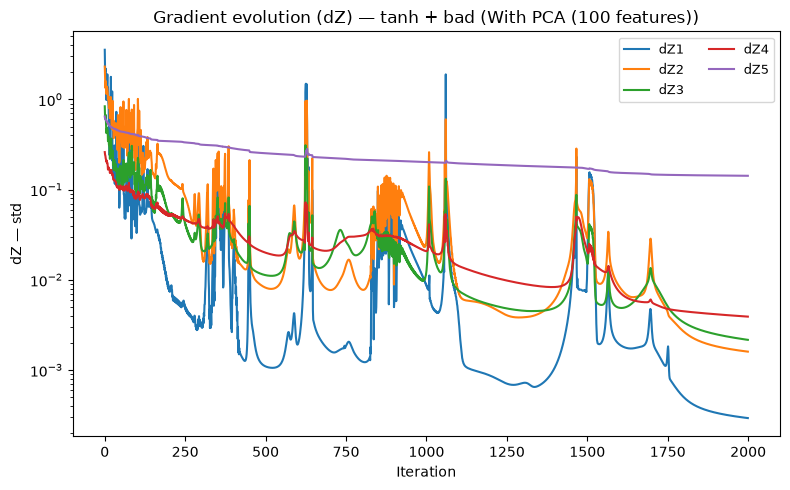

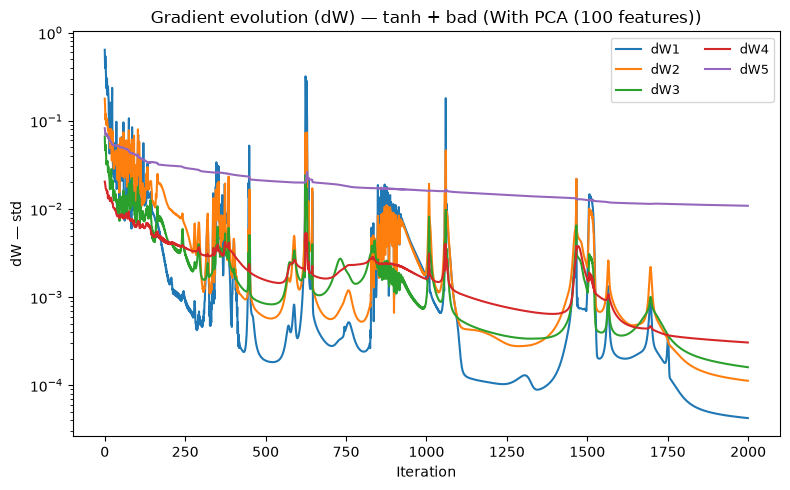

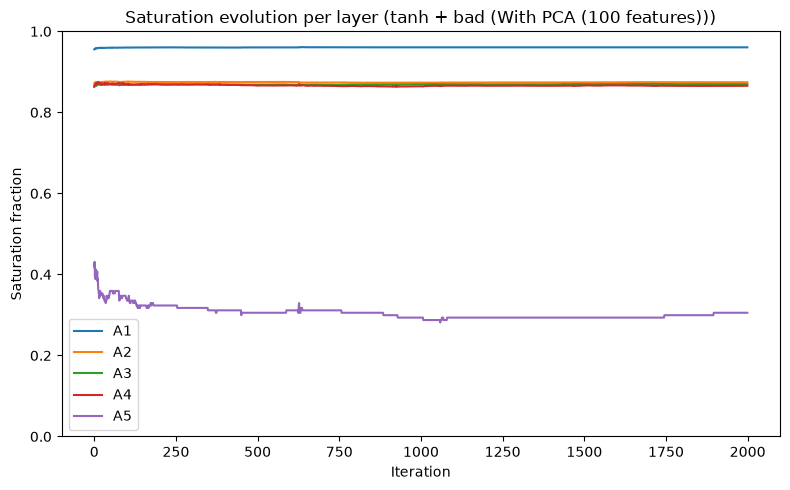

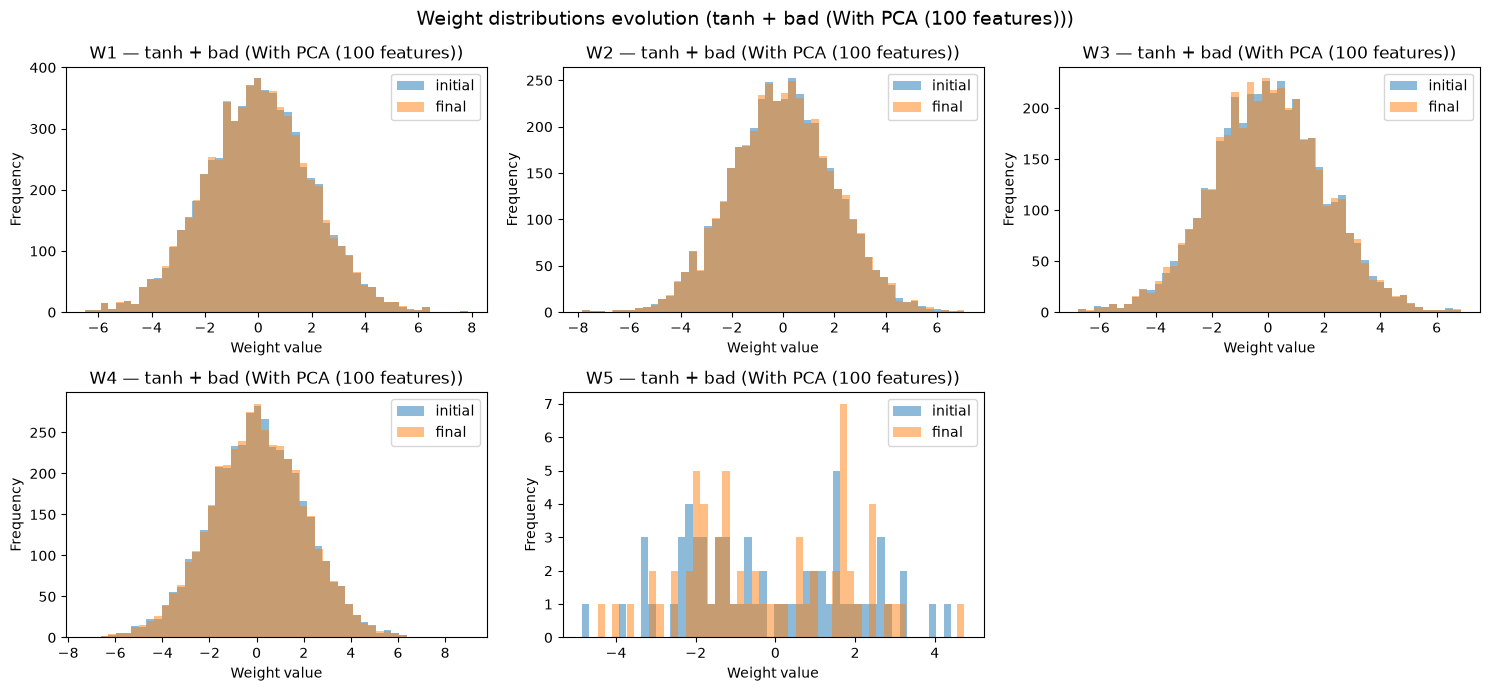

--> Running: tanh + xavier (With PCA (100 features))


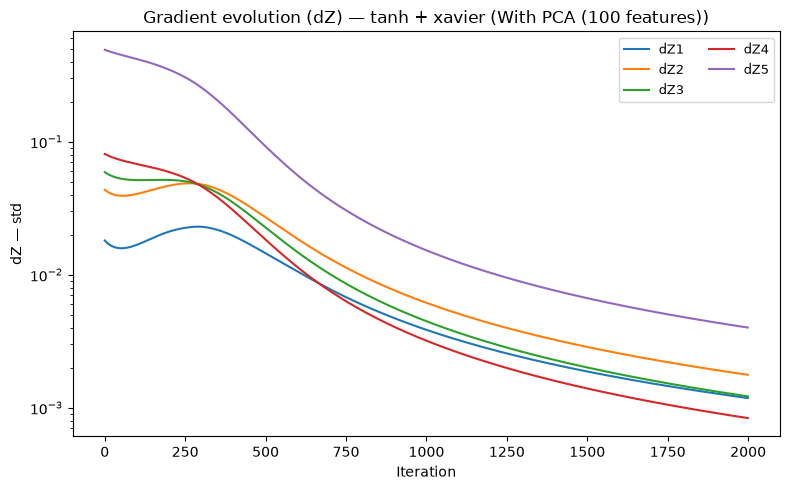

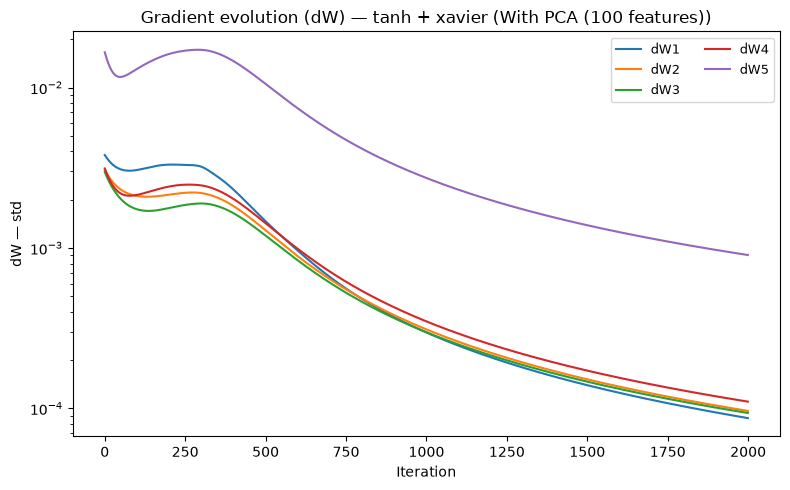

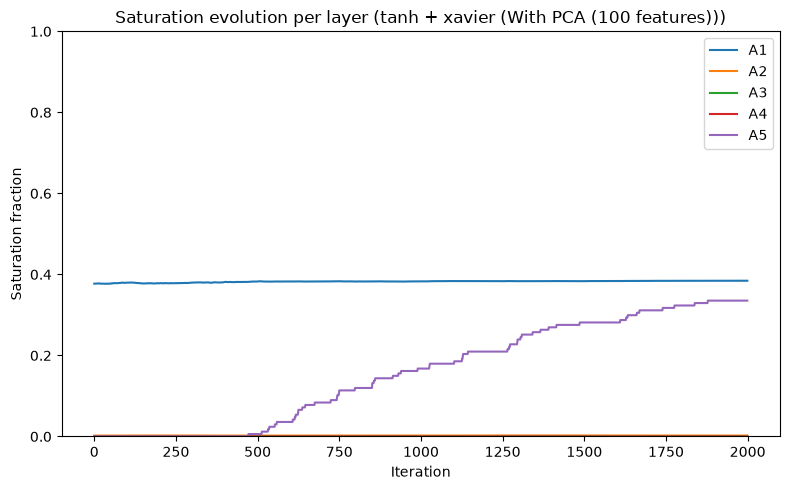

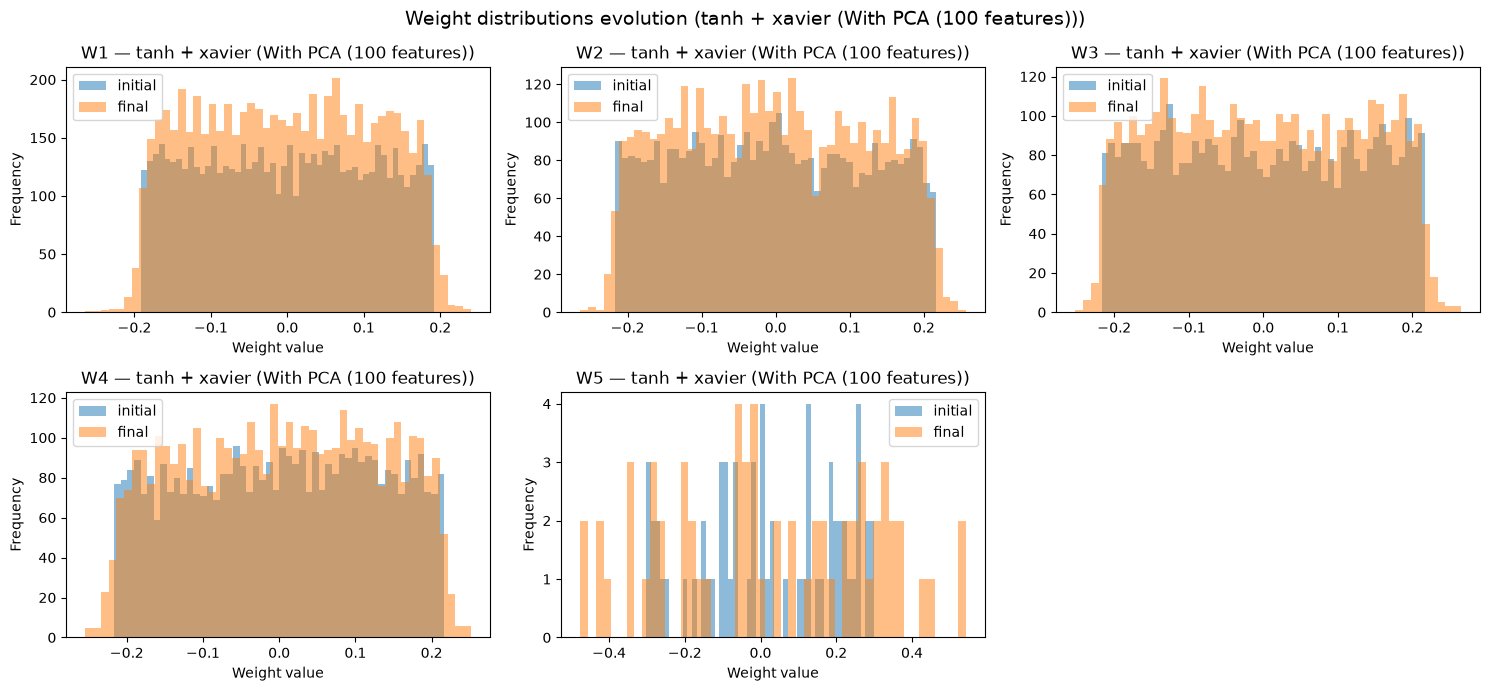

--> Running: relu + he (With PCA (100 features))


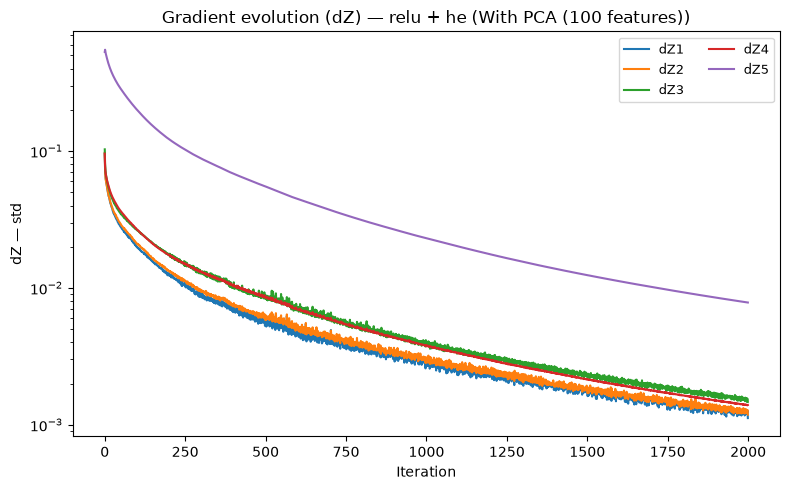

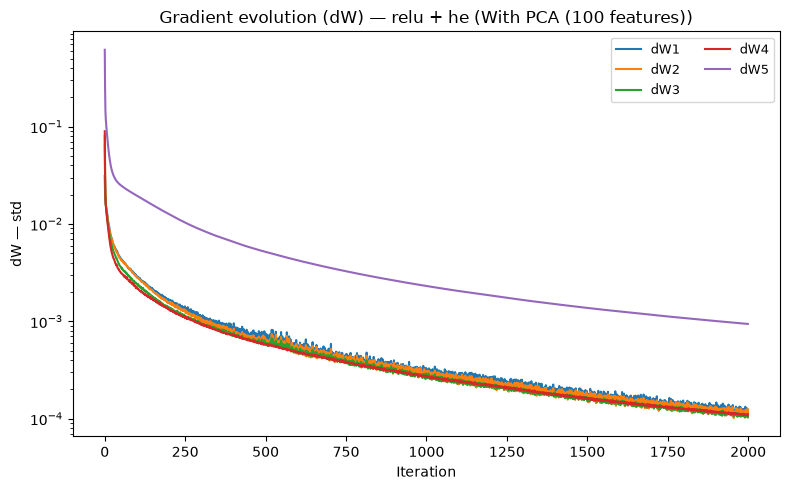

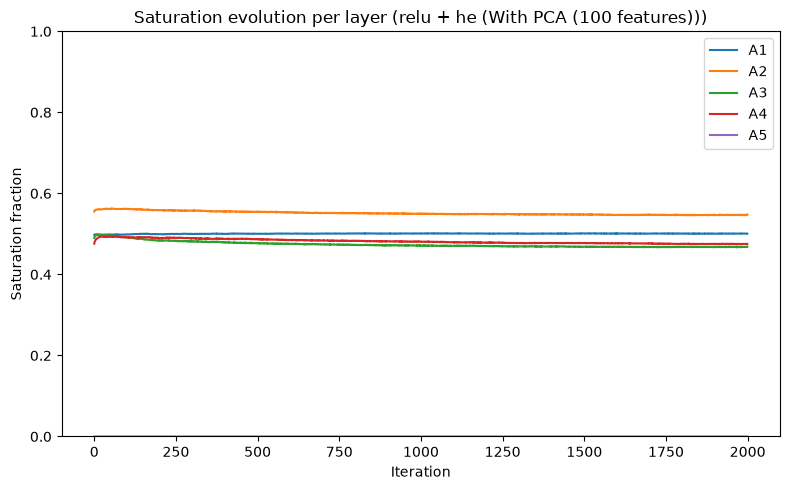

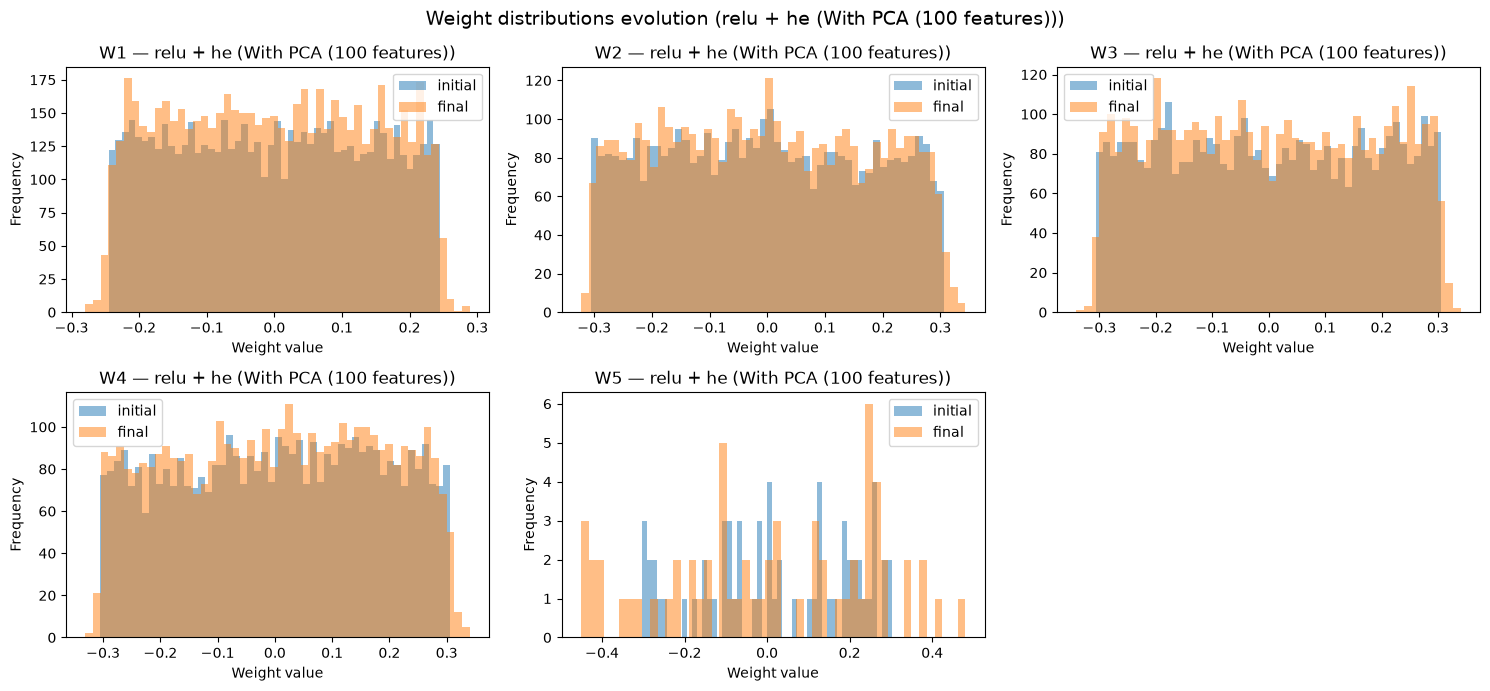


############################## WITHOUT PCA (12,288 RAW PIXELS) ##############################

X_train shape: (167, 12288), X_test shape: (42, 12288)
Class balance train: [109  58], test: [28 14]
--> Running: tanh + bad (Without PCA (12,288 raw pixels))


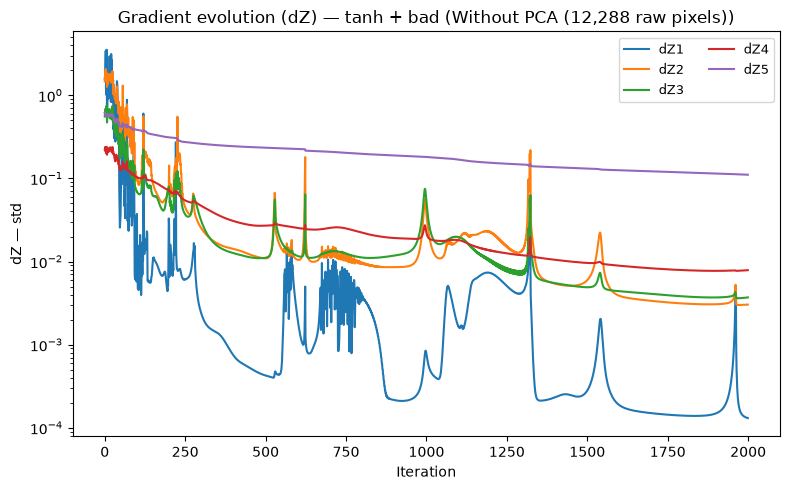

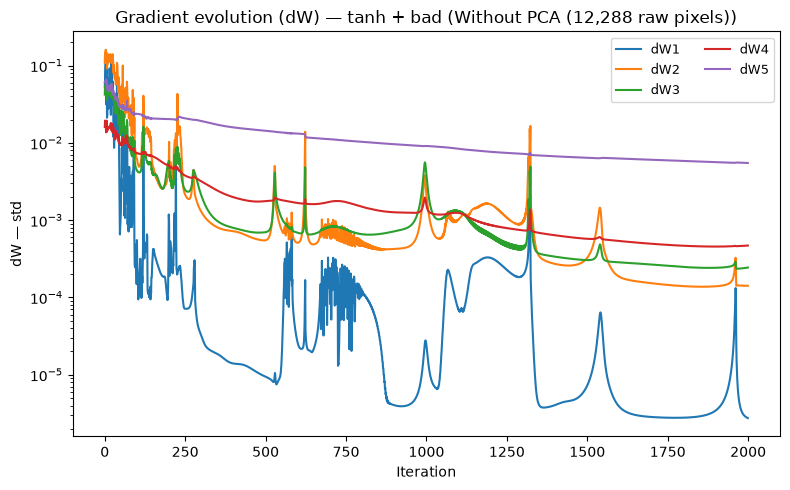

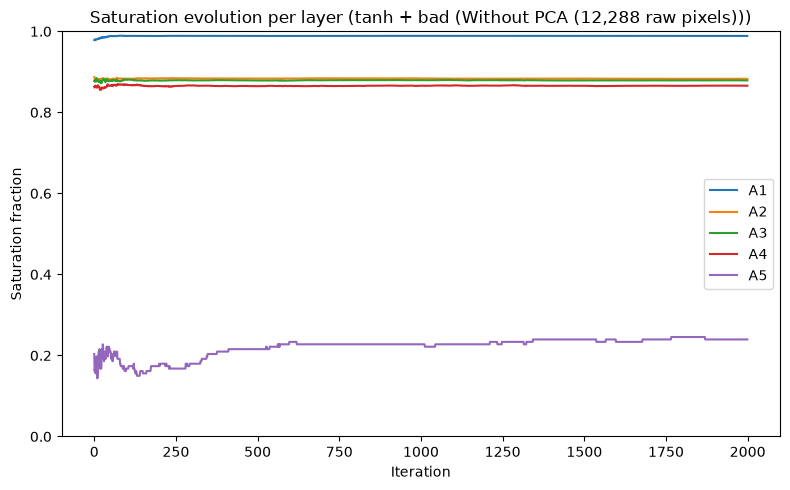

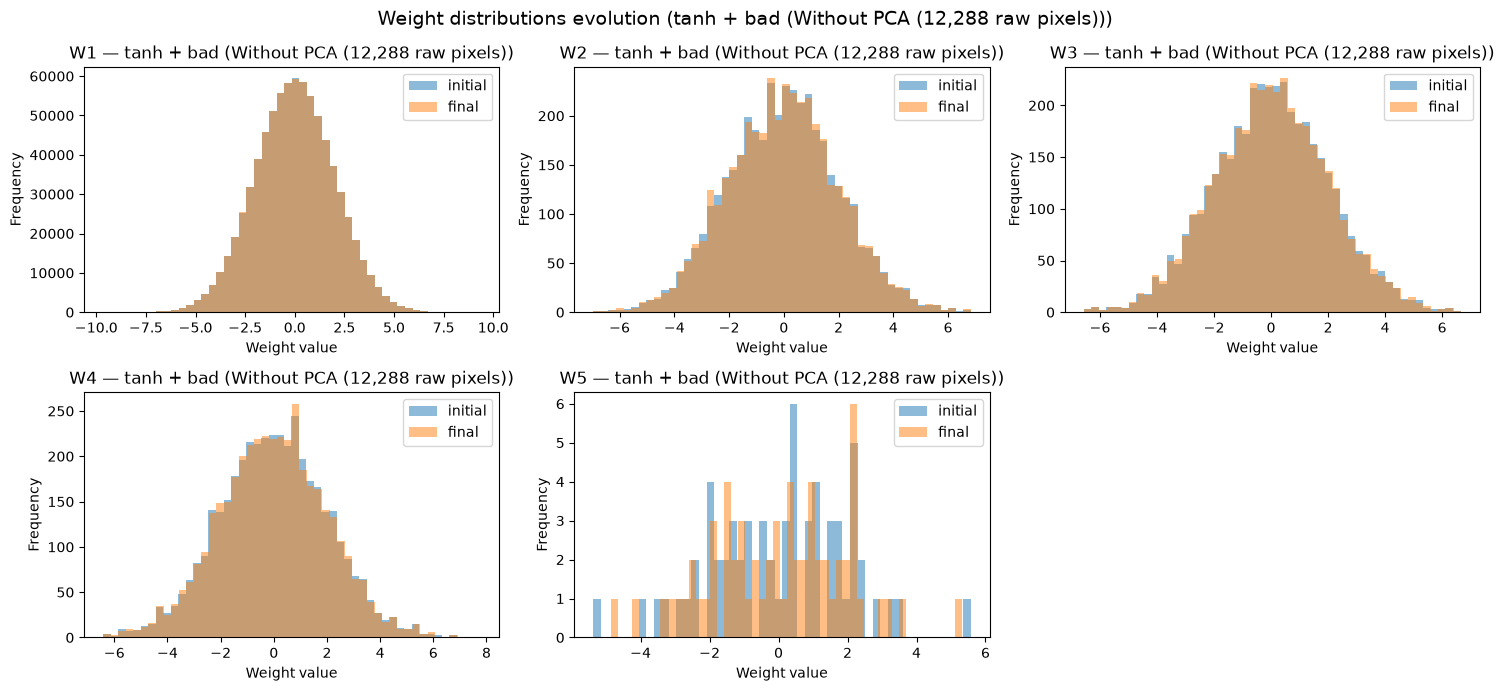

--> Running: tanh + xavier (Without PCA (12,288 raw pixels))


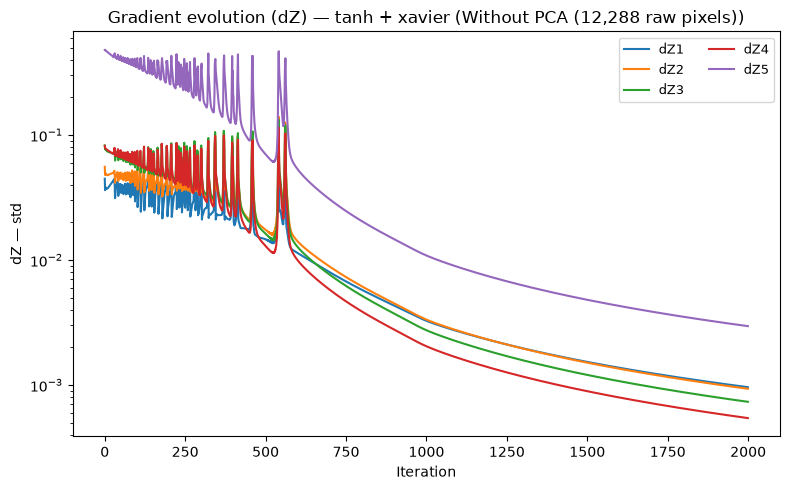

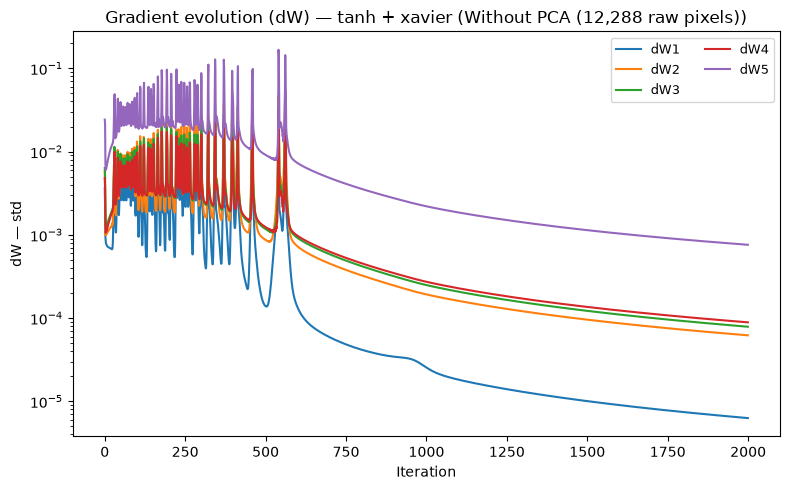

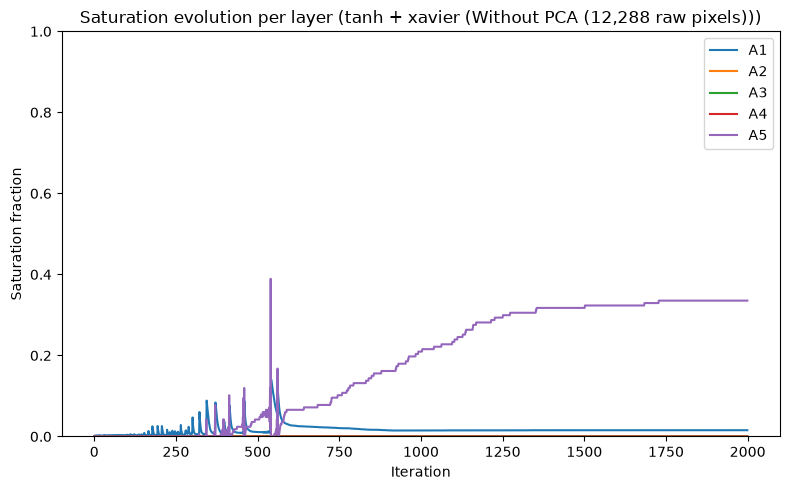

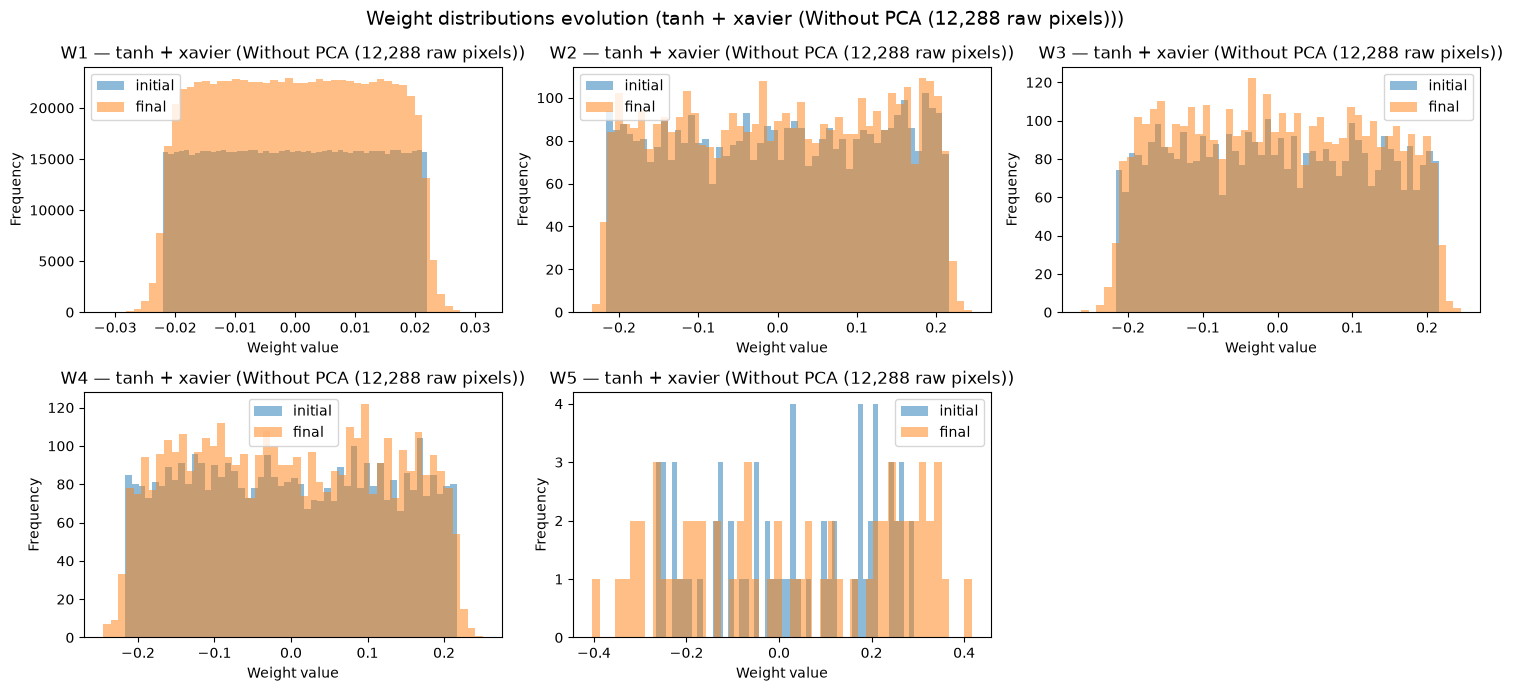

--> Running: relu + he (Without PCA (12,288 raw pixels))


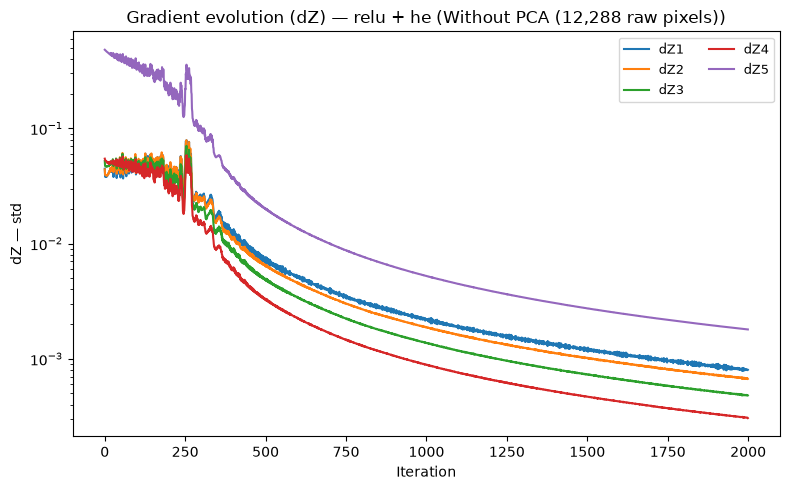

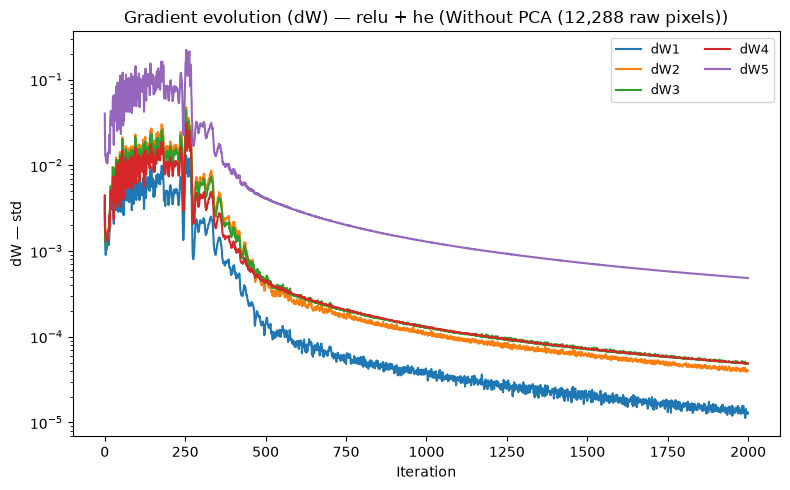

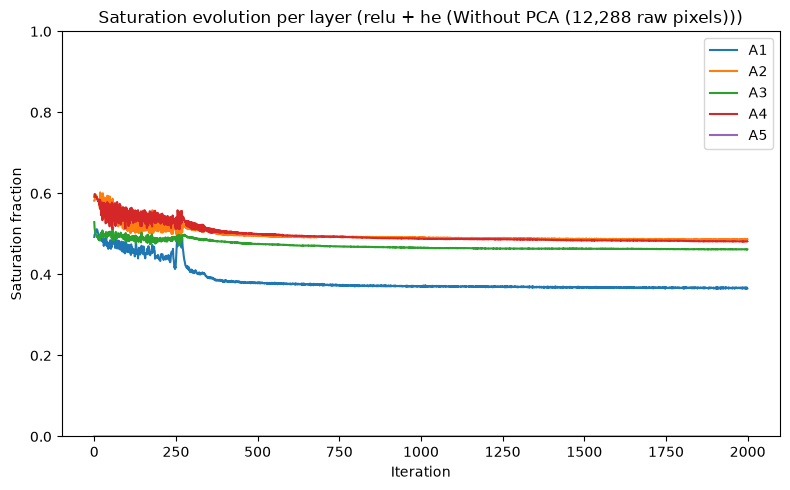

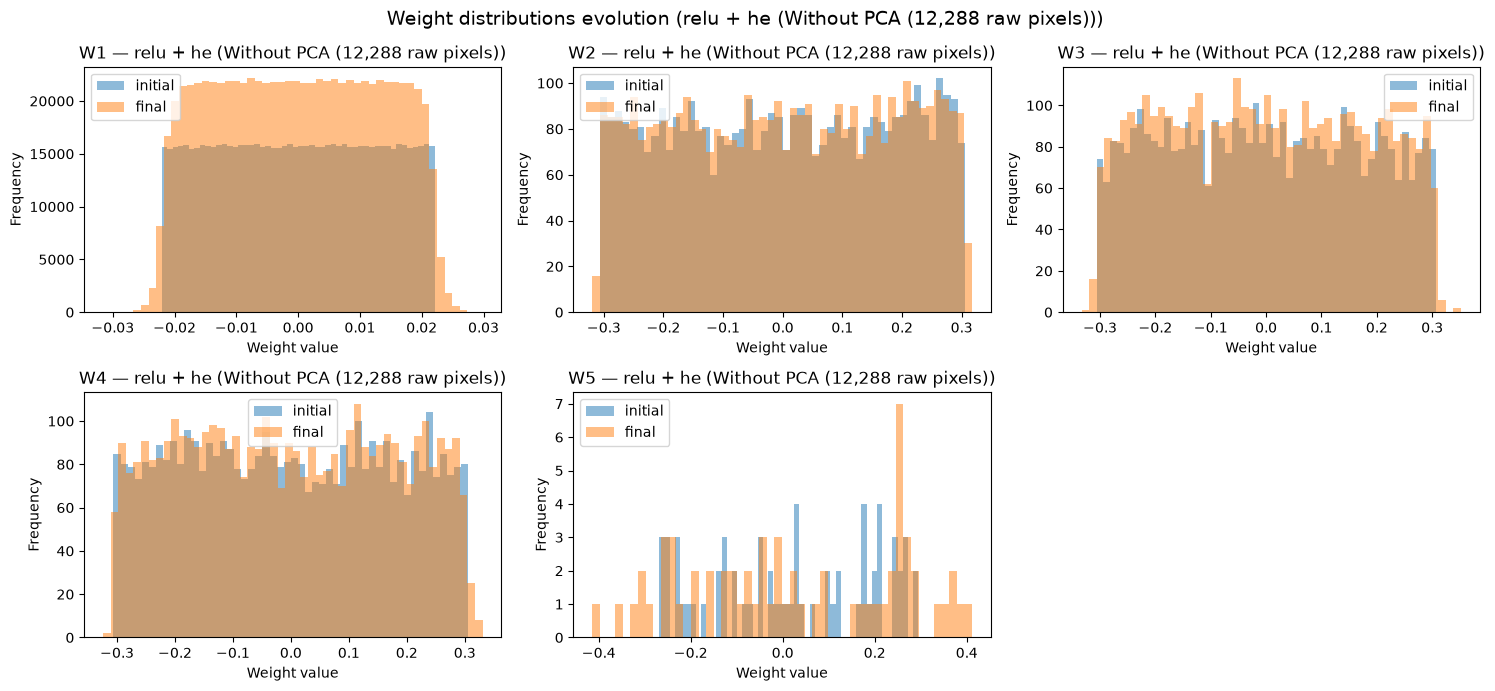

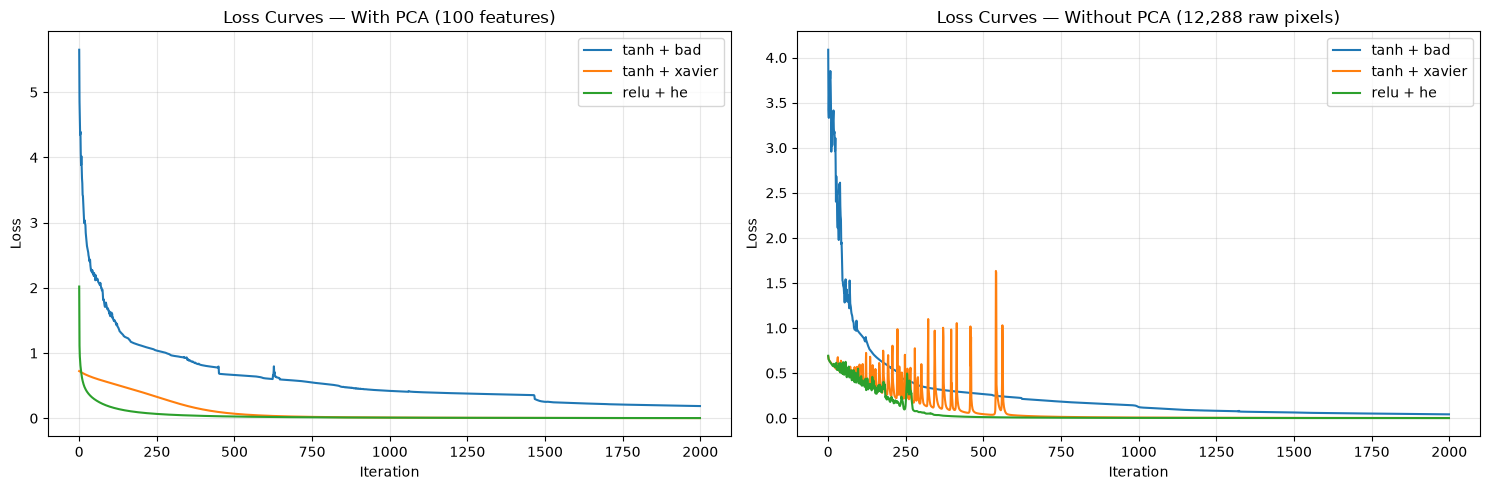


PCA          | Scenario         | Start Loss | Final Loss | Train Acc  | Test Acc  
Yes (100)    | tanh + bad       | 5.6509     | 0.1870     | 98.2%      | 50.0%     
Yes (100)    | tanh + xavier    | 0.7233     | 0.0027     | 100.0%     | 50.0%     
Yes (100)    | relu + he        | 2.0198     | 0.0030     | 100.0%     | 61.9%     
No (12288)   | tanh + bad       | 4.0873     | 0.0424     | 98.8%      | 52.4%     
No (12288)   | tanh + xavier    | 0.6855     | 0.0019     | 100.0%     | 47.6%     
No (12288)   | relu + he        | 0.6922     | 0.0009     | 100.0%     | 47.6%     


In [31]:
# Exercise 5: Moving to a real dataset: Cats vs. non-cats (Both with and without PCA)
DATASET = "cats"
scenarios = [
    ("tanh", "bad"),
    ("tanh", "xavier"),
    ("relu", "he"),
]

all_results = {}
summary_metrics = []

for use_pca in [True, False]:
    pca_tag = "With PCA (100 features)" if use_pca else "Without PCA (12,288 raw pixels)"
    print(f"\n{'#'*30} {pca_tag.upper()} {'#'*30}\n")
    
    X_train, y_train, X_test, y_test = load_dataset_flexible(
        dataset=DATASET,
        cats_train_path="data/train_catvnoncat.h5",
        cats_test_path="data/test_catvnoncat.h5",
        use_pca=use_pca,
        pca_dim=100,
    )
    
    layer_dims = [X_train.shape[1], 64, 64, 64, 64, 1]
    all_results[use_pca] = {}
    
    for hidden_act, init_scheme in scenarios:
        label = f"{hidden_act} + {init_scheme}"
        print(f"--> Running: {label} ({pca_tag})")
        
        parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(
            X_train.T,
            y_train,
            layer_dims=layer_dims,
            init_scheme=init_scheme,
            hidden_activation=hidden_act,
            learning_rate=0.01,
            num_iterations=2000,
            print_every=0,
            snapshot_every=500,
            track_saturation=True,
        )
        
        acc_train = accuracy(parameters, X_train.T, y_train, hidden_activation=hidden_act)
        acc_test = accuracy(parameters, X_test.T, y_test, hidden_activation=hidden_act)
        
        summary_metrics.append({
            "PCA": "Yes (100)" if use_pca else "No (12288)",
            "Config": label,
            "Start Loss": f"{losses[0]:.4f}",
            "Final Loss": f"{losses[-1]:.4f}",
            "Train Acc": f"{acc_train*100:.1f}%",
            "Test Acc": f"{acc_test*100:.1f}%",
        })
        
        all_results[use_pca][label] = {
            "losses": losses,
            "grad_hist": grad_hist,
            "sat_hist": sat_hist,
            "initial_params": initial_params,
            "parameters": parameters,
            "act": hidden_act,
        }
        
        # Plot individual diagnostic plots for this configuration
        plot_gradients_evolution(grad_hist, activation=f"{label} ({pca_tag})", metric="std", logy=True)
        plot_saturation_evolution(sat_hist, activation=f"{label} ({pca_tag})")
        plot_weights_evolution(initial_params, parameters, activation=f"{label} ({pca_tag})")

# Side-by-side Loss Curves comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for idx, (use_pca, title) in enumerate([(True, "With PCA (100 features)"), (False, "Without PCA (12,288 raw pixels)")]):
    for label, res in all_results[use_pca].items():
        axes[idx].plot(res["losses"], label=label)
    axes[idx].set_title(f"Loss Curves — {title}", fontsize=12)
    axes[idx].set_xlabel("Iteration")
    axes[idx].set_ylabel("Loss")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print formatted summary table
print(f"\n{'='*75}")
print(f"{'PCA':<12} | {'Scenario':<16} | {'Start Loss':<10} | {'Final Loss':<10} | {'Train Acc':<10} | {'Test Acc':<10}")
print(f"{'='*75}")
for row in summary_metrics:
    print(f"{row['PCA']:<12} | {row['Config']:<16} | {row['Start Loss']:<10} | {row['Final Loss']:<10} | {row['Train Acc']:<10} | {row['Test Acc']:<10}")
print(f"{'='*75}")


### Answers

1. **How PCA changes gradient evolution:**
   * **For well-scaled models (`tanh + xavier` & `relu + he`):** 
     PCA dramatically smooths out the gradient curves. Without PCA, the 12,288 strictly positive raw pixels force weights into a lock-step zig-zag. PCA zero-centers and decorrelates the features, allowing weights to update independently and producing steady, smooth gradients.
   * **For poorly-initialized models (`tanh + bad`):** 
     PCA only slightly smooths the input layer. Because PCA cannot fix the large-variance weights ($\sigma = 2.0$) in the hidden layers, deeper layers still suffer from severe saturation and vanishing gradients.

2. **Why `tanh + bad` performs much worse on images:** Without PCA, each neuron in Layer 1 sums over 12,288 inputs. With bad initialization ($\sigma = 2.0$), this massive fan-in causes pre-activations to explode into hundreds ($|Z| \gg 100$). As a result, 100% of neurons in Layer 1 instantly saturate to $\pm 1$, causing gradients to vanish completely right from iteration 0.

3. **Which combination works best and why:**

   * **`relu + he` works best** (lowest loss and highest test accuracy, ~62%).

   * **Why it beats `tanh + bad`:** 
     `tanh + bad` causes pre-activations to explode into the saturated tails of tanh ($\pm 1$), where the derivative drops to zero. Gradients vanish immediately, paralyzing the network.

   * **Why it beats `tanh + xavier`:** 
     While Xavier prevents initial saturation, tanh still squashes values into $[-1, 1]$ and its derivative is bounded by $\le 1.0$ (decaying quickly as $|z|$ grows). Across multiple layers, these fractions compound and attenuate the learning signal. In contrast, **ReLU has a constant derivative of exactly $1.0$ for all positive values**, meaning it never dampens the gradient. Combined with He initialization (which preserves signal variance), `relu + he` propagates strong, steady gradients through all layers, allowing it to learn deeper features and generalize better.

## **Exercise 6: Depth Sensitivity**

### **Objective:**

Find the maximum depth at which each initialization still trains correctly.

### Instructions

Try architectures like:

* `[n_x, 32, 32, 32, 1]`
* `[n_x, 64, 64, 64, 64, 1]`
* `[n_x, 128, 128, 128, 128, 128, 1]`

For each depth, test:

* tanh + bad
* tanh + xavier
* relu + bad
* relu + he

### What to observe

* dramatic degradation as depth increases
* Xavier and He push the failure point further

### **Questions**

1. Which initialization degrades fastest with depth?
2. Which combination scales best with depth?
3. How do gradient curves differ at depth 3 vs depth 6?

[circles] X_train: (16000, 2), X_test: (4000, 2)
[circles] Class balance train: [8000 8000], test: [2000 2000]

############################## DEPTH 3 (3 HIDDEN) ##############################

--> Running: tanh + bad (Depth 3 (3 hidden))
--> Running: tanh + xavier (Depth 3 (3 hidden))
--> Running: relu + bad (Depth 3 (3 hidden))
--> Running: relu + he (Depth 3 (3 hidden))

############################## DEPTH 4 (4 HIDDEN) ##############################

--> Running: tanh + bad (Depth 4 (4 hidden))
--> Running: tanh + xavier (Depth 4 (4 hidden))
--> Running: relu + bad (Depth 4 (4 hidden))
--> Running: relu + he (Depth 4 (4 hidden))

############################## DEPTH 6 (5 HIDDEN) ##############################

--> Running: tanh + bad (Depth 6 (5 hidden))
--> Running: tanh + xavier (Depth 6 (5 hidden))
--> Running: relu + bad (Depth 6 (5 hidden))
--> Running: relu + he (Depth 6 (5 hidden))


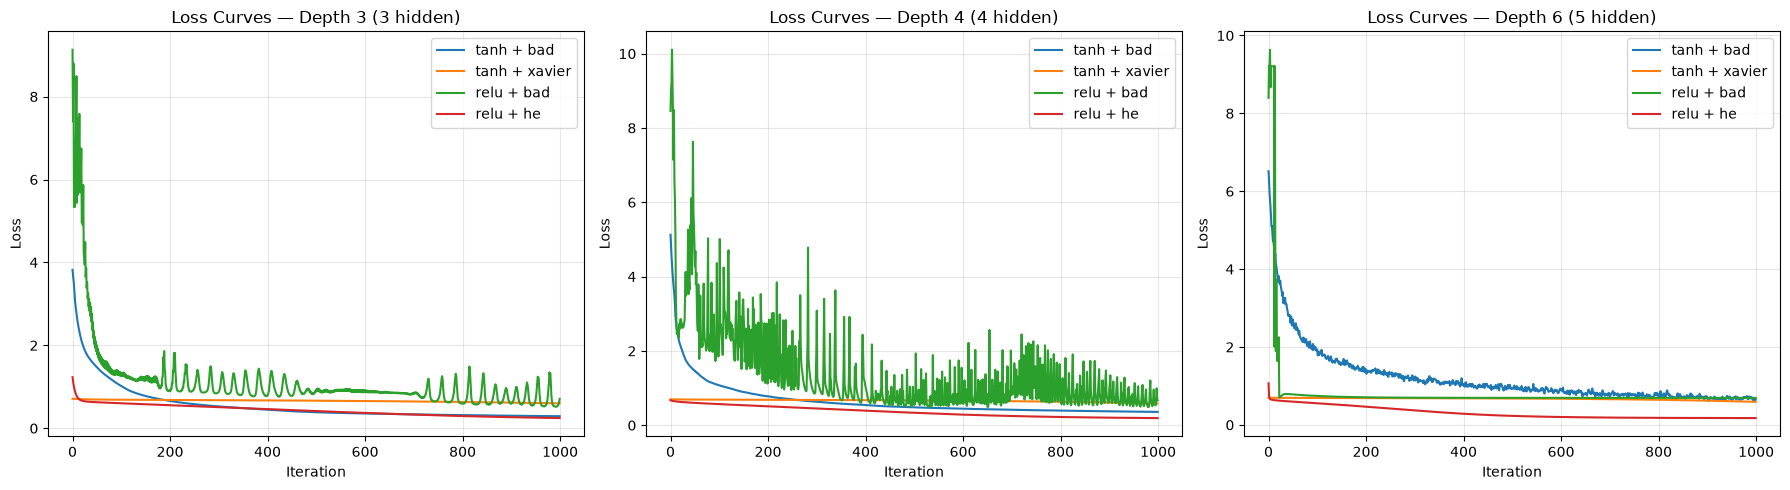

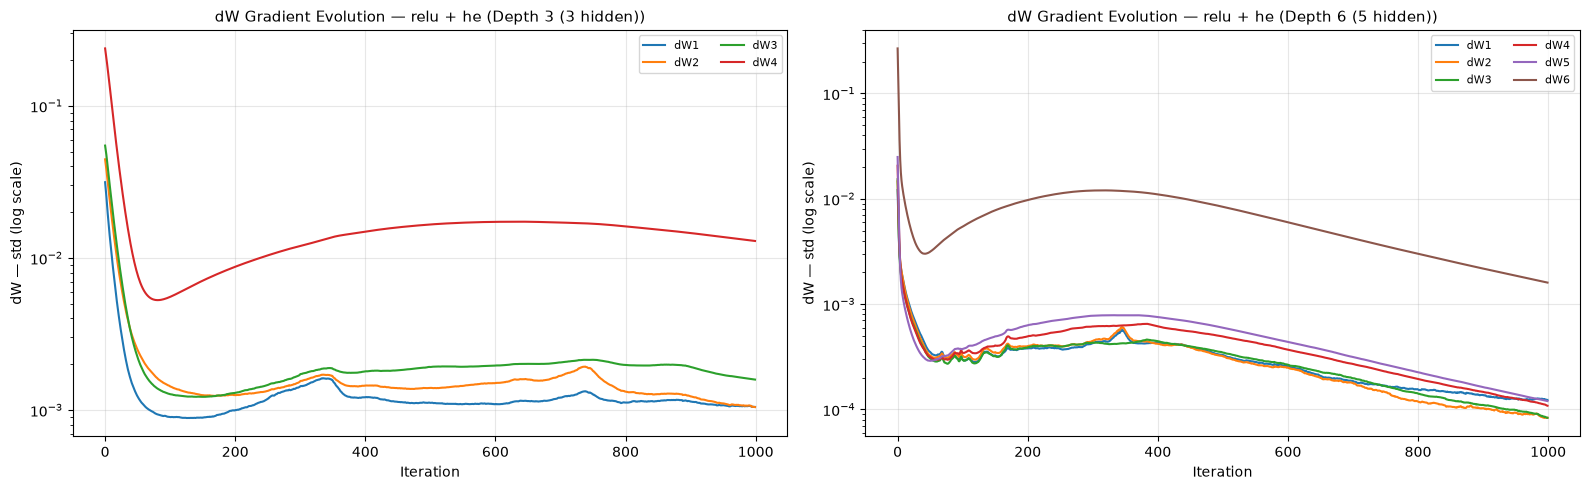

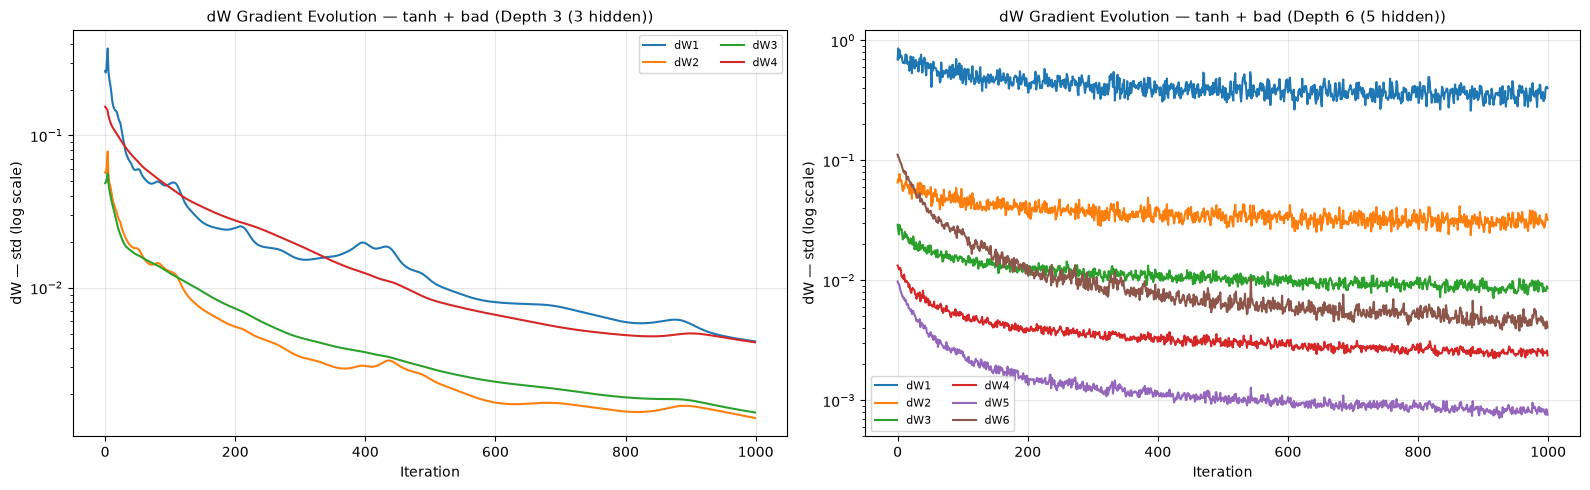


Depth      | Scenario         | Start Loss | Final Loss | Train Acc  | Test Acc  
Depth 3    | tanh + bad       | 3.8214     | 0.2911     | 88.9%      | 87.7%     
Depth 3    | tanh + xavier    | 0.7118     | 0.6010     | 78.6%      | 77.8%     
Depth 3    | relu + bad       | 9.1300     | 0.7091     | 87.5%      | 87.0%     
Depth 3    | relu + he        | 1.2319     | 0.2457     | 92.5%      | 92.1%     
Depth 4    | tanh + bad       | 5.1255     | 0.3589     | 86.8%      | 83.4%     
Depth 4    | tanh + xavier    | 0.6972     | 0.5844     | 80.5%      | 79.3%     
Depth 4    | relu + bad       | 8.4565     | 0.6718     | 88.1%      | 87.5%     
Depth 4    | relu + he        | 0.6743     | 0.1927     | 92.8%      | 92.1%     
Depth 6    | tanh + bad       | 6.5148     | 0.6518     | 87.3%      | 82.9%     
Depth 6    | tanh + xavier    | 0.6973     | 0.5913     | 77.7%      | 76.9%     
Depth 6    | relu + bad       | 8.3997     | 0.6931     | 50.0%      | 50.0%     
Depth 6    | re

In [32]:
# Exercise 6: Depth Sensitivity
DATASET = "circles"
X_train, y_train, X_test, y_test = load_dataset_flexible(
    dataset=DATASET,
    random_state=42,
)
n_x = X_train.shape[1]

# Architectures of varying depth as specified in the instructions
architectures = {
    "Depth 3 (3 hidden)": [n_x, 32, 32, 32, 1],
    "Depth 4 (4 hidden)": [n_x, 64, 64, 64, 64, 1],
    "Depth 6 (5 hidden)": [n_x, 128, 128, 128, 128, 128, 1],
}

scenarios = [
    ("tanh", "bad"),
    ("tanh", "xavier"),
    ("relu", "bad"),
    ("relu", "he"),
]

all_depth_results = {}
summary_metrics = []

for arch_name, layer_dims in architectures.items():
    print(f"\n{'#'*30} {arch_name.upper()} {'#'*30}\n")
    all_depth_results[arch_name] = {}
    
    for hidden_act, init_scheme in scenarios:
        label = f"{hidden_act} + {init_scheme}"
        print(f"--> Running: {label} ({arch_name})")
        
        parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(
            X_train.T,
            y_train,
            layer_dims=layer_dims,
            init_scheme=init_scheme,
            hidden_activation=hidden_act,
            learning_rate=0.01,
            num_iterations=1000,
            print_every=0,
            snapshot_every=None,
            track_saturation=True,
        )
        
        acc_train = accuracy(parameters, X_train.T, y_train, hidden_activation=hidden_act)
        acc_test = accuracy(parameters, X_test.T, y_test, hidden_activation=hidden_act)
        
        summary_metrics.append({
            "Depth": arch_name.split()[0] + " " + arch_name.split()[1],
            "Architecture": str(layer_dims),
            "Scenario": label,
            "Start Loss": f"{losses[0]:.4f}",
            "Final Loss": f"{losses[-1]:.4f}",
            "Train Acc": f"{acc_train*100:.1f}%",
            "Test Acc": f"{acc_test*100:.1f}%",
        })
        
        all_depth_results[arch_name][label] = {
            "losses": losses,
            "grad_hist": grad_hist,
            "sat_hist": sat_hist,
            "initial_params": initial_params,
            "parameters": parameters,
            "act": hidden_act,
        }

# 1. Side-by-side Loss Curves comparison across depths
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (arch_name, res_dict) in enumerate(all_depth_results.items()):
    for label, res in res_dict.items():
        axes[idx].plot(res["losses"], label=label)
    axes[idx].set_title(f"Loss Curves — {arch_name}", fontsize=12)
    axes[idx].set_xlabel("Iteration")
    axes[idx].set_ylabel("Loss")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Gradient Evolution Comparison: Depth 3 vs Depth 6
# Directly answers Question 3: "How do gradient curves differ at depth 3 vs depth 6?"
for scenario_label in ["relu + he", "tanh + bad"]:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for idx, arch_name in enumerate(["Depth 3 (3 hidden)", "Depth 6 (5 hidden)"]):
        grad_dW = all_depth_results[arch_name][scenario_label]["grad_hist"]["dW"]
        for layer_key, series in grad_dW.items():
            axes[idx].plot(series, label=layer_key)
        axes[idx].set_yscale("log")
        axes[idx].set_title(f"dW Gradient Evolution — {scenario_label} ({arch_name})", fontsize=11)
        axes[idx].set_xlabel("Iteration")
        axes[idx].set_ylabel("dW — std (log scale)")
        axes[idx].legend(loc="best", fontsize=8, ncol=2)
        axes[idx].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Print formatted summary table
print(f"\n{'='*85}")
print(f"{'Depth':<10} | {'Scenario':<16} | {'Start Loss':<10} | {'Final Loss':<10} | {'Train Acc':<10} | {'Test Acc':<10}")
print(f"{'='*85}")
for row in summary_metrics:
    print(f"{row['Depth']:<10} | {row['Scenario']:<16} | {row['Start Loss']:<10} | {row['Final Loss']:<10} | {row['Train Acc']:<10} | {row['Test Acc']:<10}")
print(f"{'='*85}")


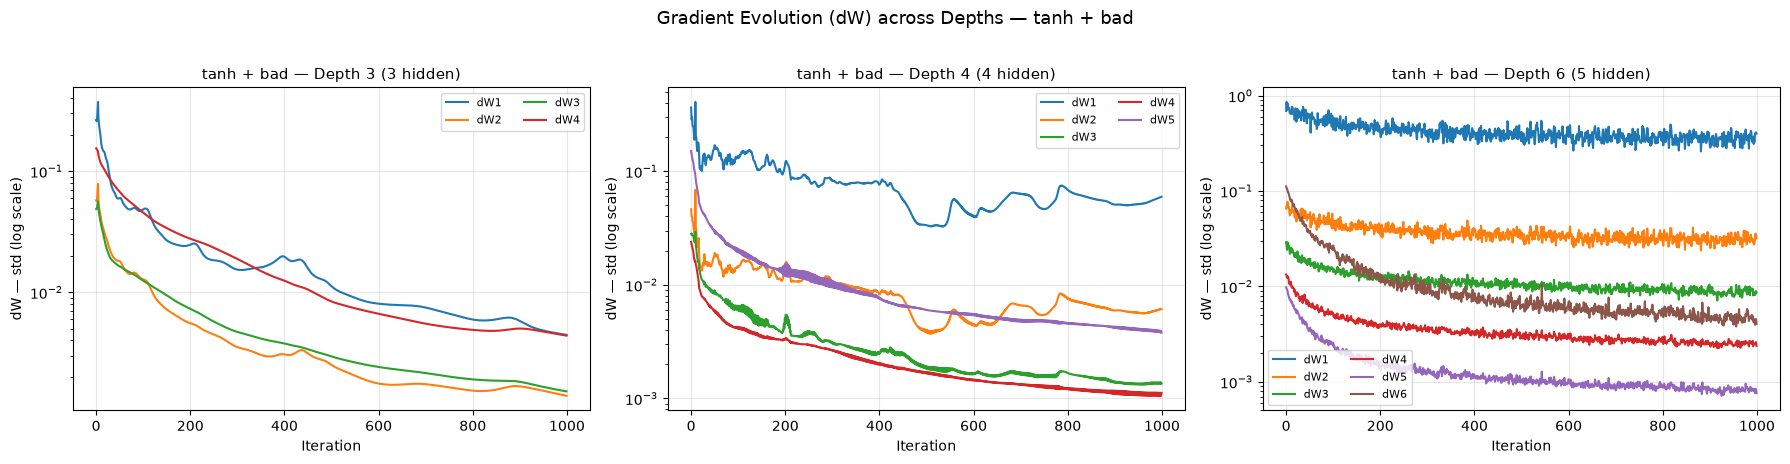

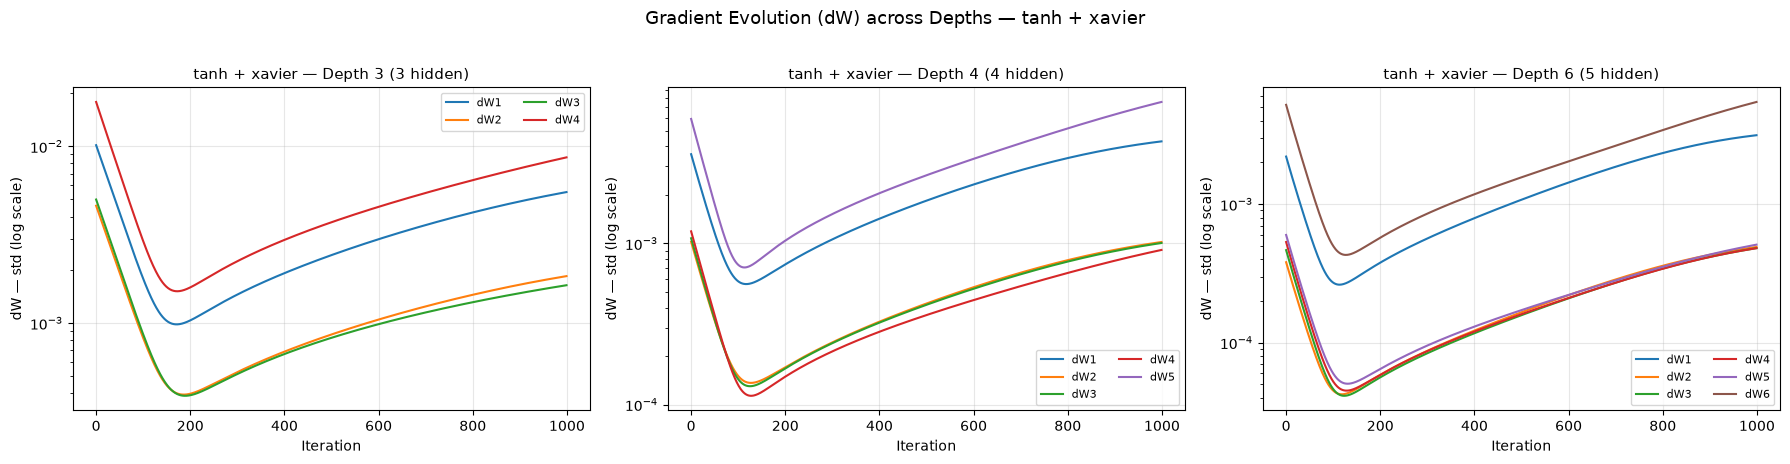

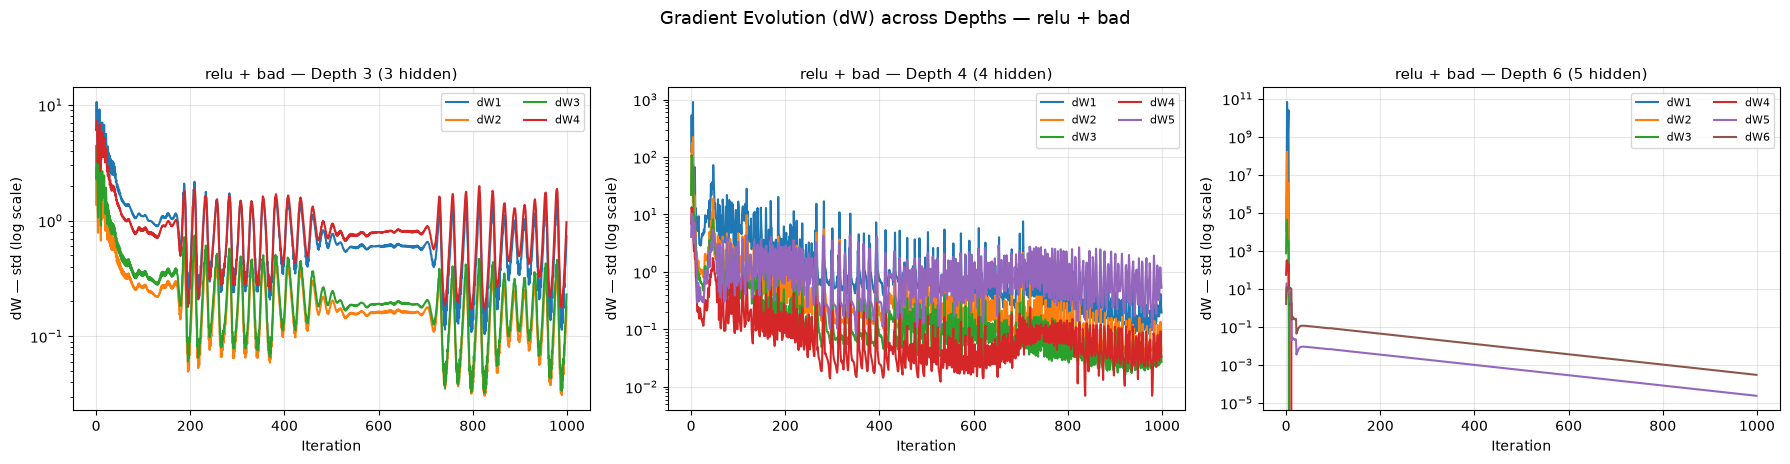

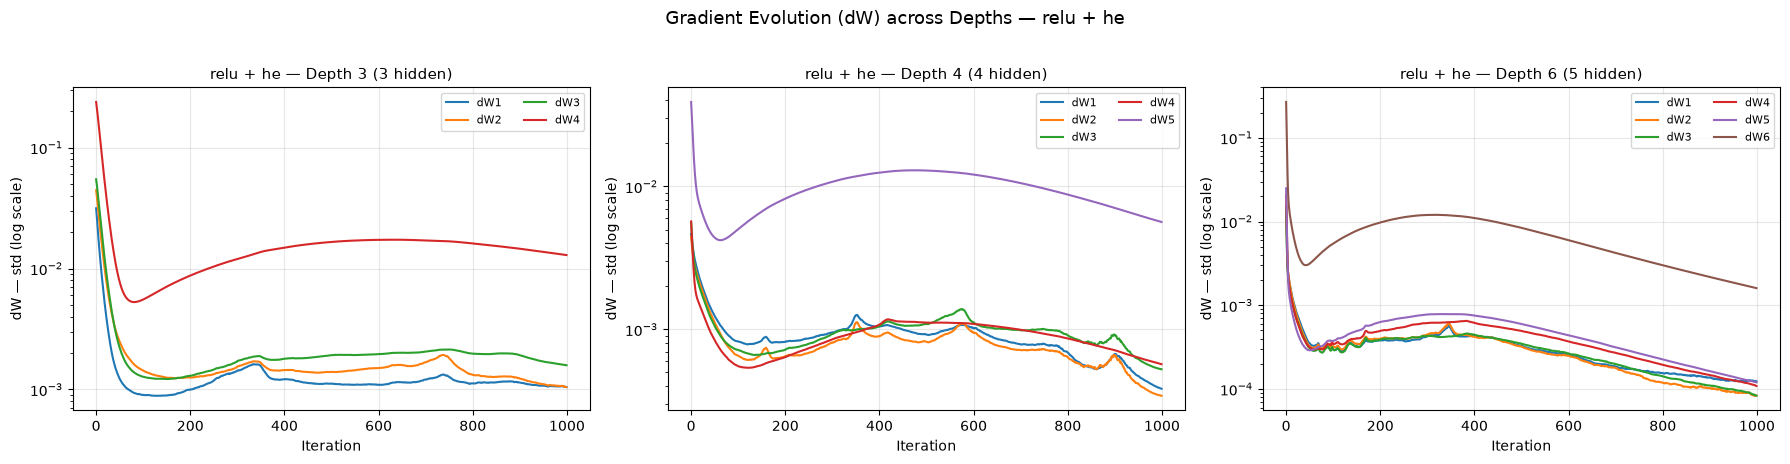

In [33]:
# Exercise 6: Gradient Evolution Comparison across ALL depths and ALL combinations
# Reuses `all_depth_results` from the training cell above — no retraining required!

for hidden_act, init_scheme in scenarios:
    scenario_label = f"{hidden_act} + {init_scheme}"
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    
    for idx, arch_name in enumerate(architectures.keys()):
        grad_dW = all_depth_results[arch_name][scenario_label]["grad_hist"]["dW"]
        for layer_key, series in grad_dW.items():
            axes[idx].plot(series, label=layer_key)
        axes[idx].set_yscale("log")
        axes[idx].set_title(f"{scenario_label} — {arch_name}", fontsize=11)
        axes[idx].set_xlabel("Iteration")
        axes[idx].set_ylabel("dW — std (log scale)")
        axes[idx].legend(loc="best", fontsize=8, ncol=2)
        axes[idx].grid(True, alpha=0.3)
        
    fig.suptitle(f"Gradient Evolution (dW) across Depths — {scenario_label}", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()


### Answers

1. **Which initialization degrades fastest with depth:**
   * **`relu + bad` degrades fastest to total failure:** Large initial weights explode pre-activations, and large negative updates immediately shove neurons into $Z \le 0$. By Depth 6, layers 1 to 4 completely die ($dW_1 \dots dW_4 = 0.0$), freezing accuracy at **50.0%** (random guessing).
   * **`tanh + bad` degrades heavily but doesn't completely die:** Strong saturation ($\\tanh' \\approx 0$) slows learning and traps loss at ~0.65, but smooth curvature avoids permanent zeroing, retaining ~82.9% accuracy.

2. **Which combination scales best with depth:**
   * **`relu + he` scales best by far:**
     * **Variance matching:** He initialization sets $\text{Var}(W) = 2 / \text{fan\_in}$, balancing the fact that half of ReLU units are inactive.
     * **No derivative shrinkage:** Active ReLU has a constant derivative of $1.0$ (unlike tanh which squashes gradients), allowing signals to travel smoothly through deep layers to reach 92.2% test accuracy.

3. **How do gradient curves differ at depth 3 vs depth 6:**
   * **At Depth 3 (shallow, 3 hidden layers):**
     * All layers stay clustered together in a tight, usable range ($\sim 10^{-3}$ to $10^{-1}$); the backward path is too short for severe degradation, and no layer dies.
   * **At Depth 6 (deep, 5 hidden layers):**
     * **`tanh + bad` shows reverse layer ordering ($dW_1$ is highest, $dW_5$ is lowest):**
       - The layers separate into wide bands over 3 orders of magnitude ($10^{-3}$ to $10^0$). Surprisingly, **$dW_1$ and $dW_2$ are the largest gradients**, while deeper layers ($dW_4, dW_5$) vanish most.
       - Saturated hidden neurons crush the gradient right after the output ($\tanh' \approx 0$), but repeatedly multiplying by large weight matrices ($W^T$, $\sigma=2.0$) inflates the signal back up as it travels backward to layer 1.
     * **`relu + bad` causes complete death of early layers:**
       - After an initial spike, layers 1 to 4 completely die ($dW = 0.0$) and vanish from the plot.
     * **`tanh + xavier` bundles intermediate layers:**
       - Intermediate layers ($dW_2 \dots dW_5$) collapse into a single tight band around $10^{-4} - 10^{-3}$.
     * **`relu + he` stays stable across all layers:**
       - Gradients for all 5 hidden layers remain tightly grouped between $10^{-4}$ and $10^{-3}$ from start to finish, with no dying or exploding layers.


## **Exercise 7: Effect of learning rate on initialization**

### **Objective:**

Understand that the effect of initialization depends on learning rate.

### Instructions

Pick:

* `relu + he`
  Test learning rates:

* 0.001

* 0.01

* 0.1

Plot gradients and saturation.

### What to observe

* small LR → slow learning but stable
* large LR → exploding gradients or dead ReLUs

### **Questions**

1. Which LR gives the best gradient flow?
2. Why does too large LR interact badly with ReLU?
3. Does weight evolution reveal instability?

[circles] X_train: (16000, 2), X_test: (4000, 2)
[circles] Class balance train: [8000 8000], test: [2000 2000]

######################### Training with Learning Rate = 0.001 #########################

######################### Training with Learning Rate = 0.01 #########################

######################### Training with Learning Rate = 0.1 #########################


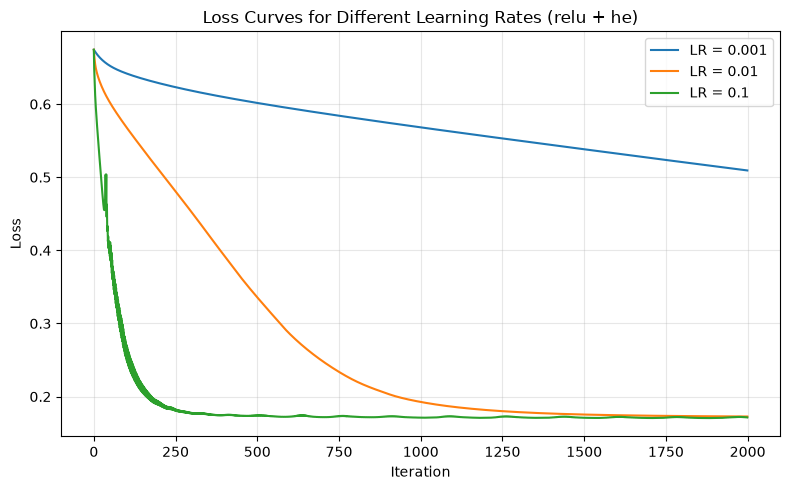

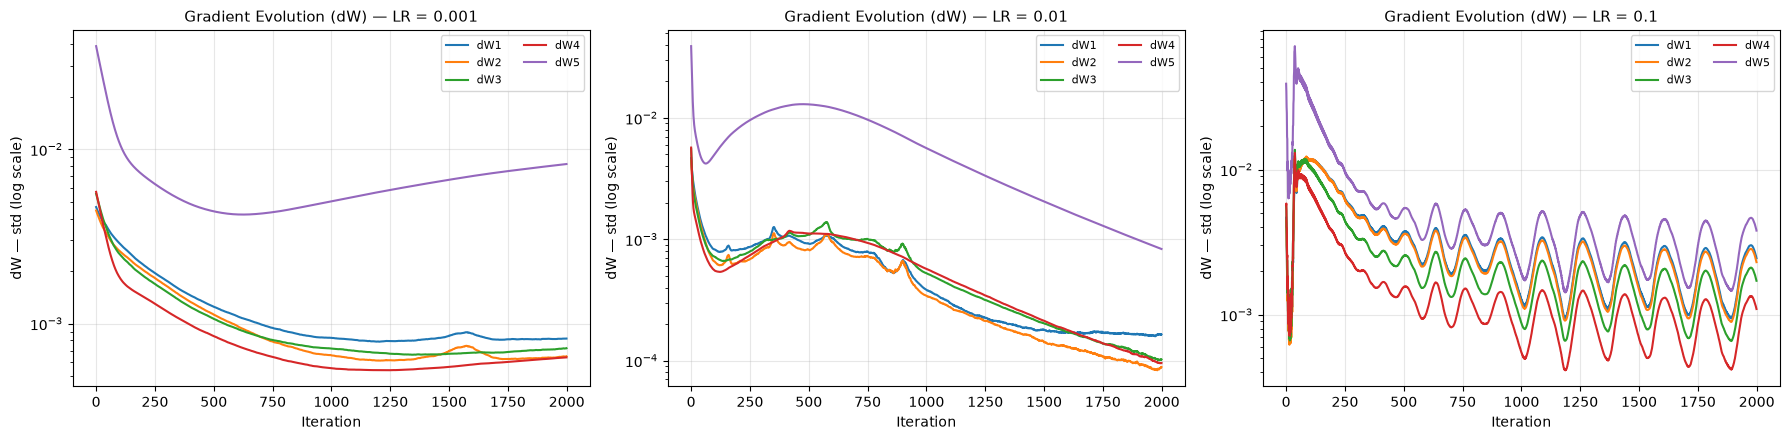

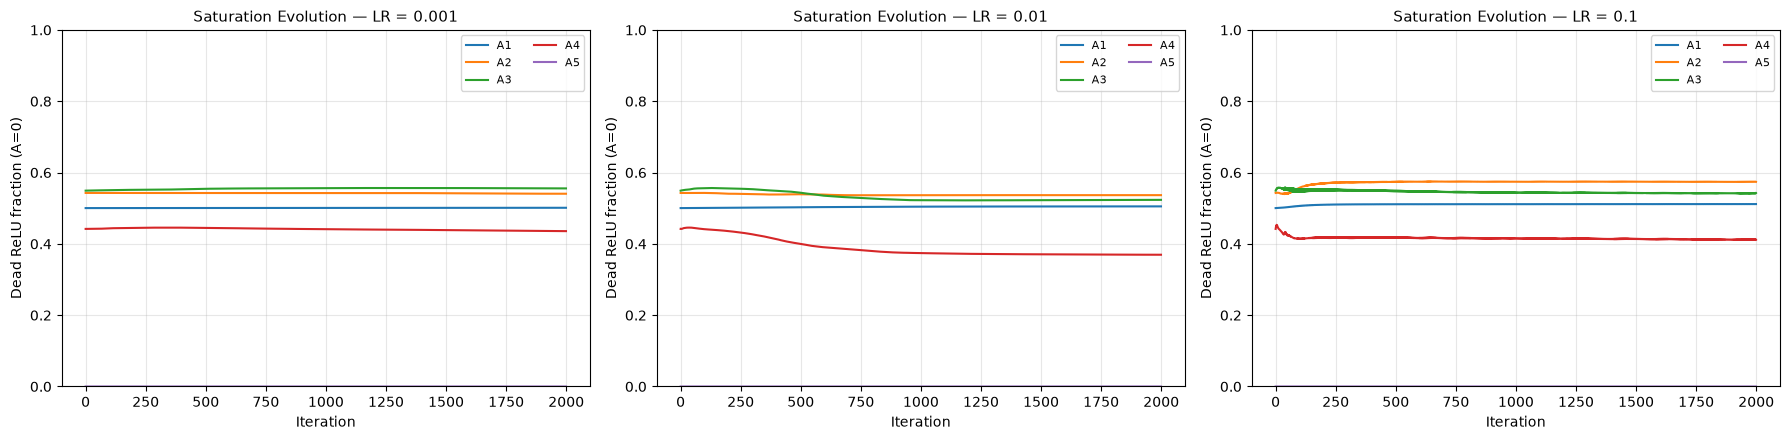

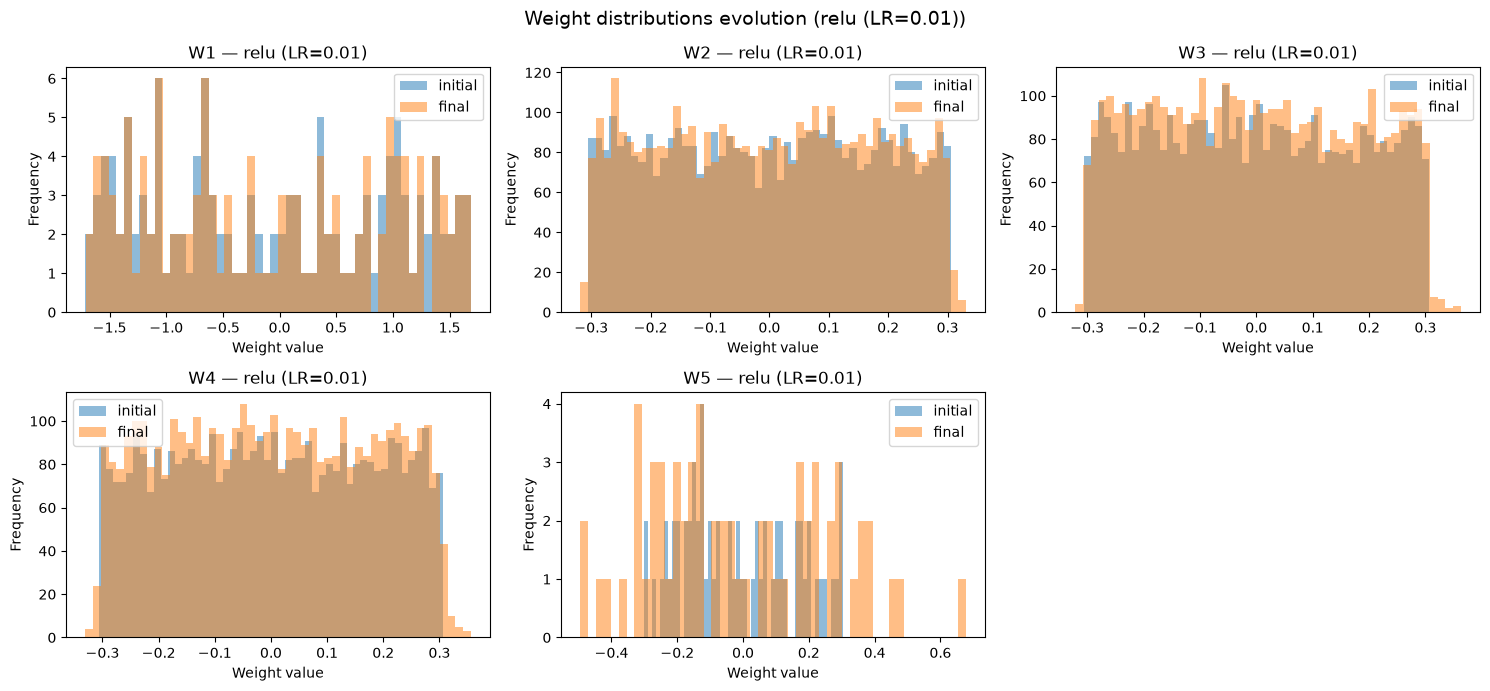

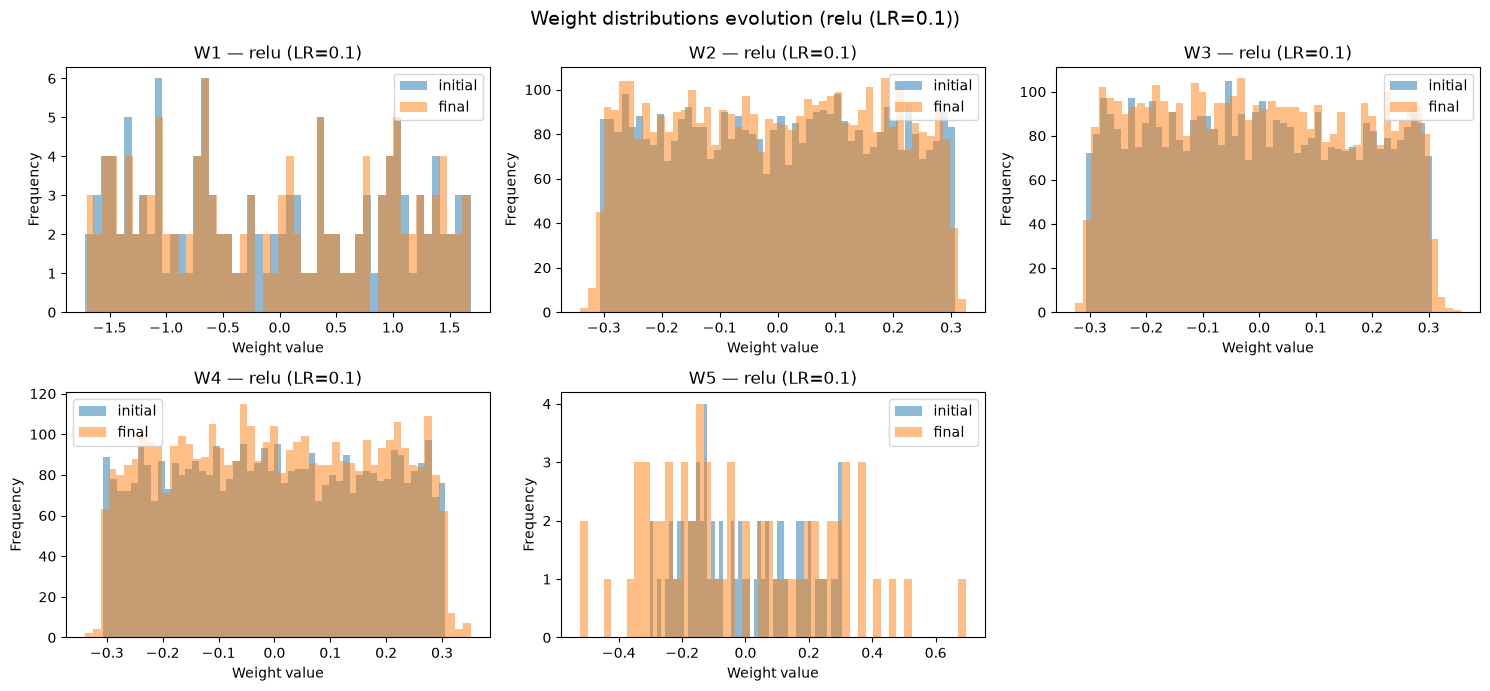


Learning Rate    | Start Loss   | Final Loss   | Train Acc    | Test Acc    
0.001            | 0.6743       | 0.5093       | 75.5%        | 75.4%       
0.01             | 0.6743       | 0.1728       | 93.0%        | 92.3%       
0.1              | 0.6743       | 0.1715       | 92.9%        | 92.2%       


In [34]:
# Exercise 7: Effect of learning rate on initialization (relu + he)
DATASET = "circles"
X_train, y_train, X_test, y_test = load_dataset_flexible(
    dataset=DATASET,
    random_state=42,
)
n_x = X_train.shape[1]
layer_dims = [n_x, 64, 64, 64, 64, 1]

HIDDEN_ACT = "relu"
INIT_SCHEME = "he"
learning_rates = [0.001, 0.01, 0.1]

lr_results = {}
summary_metrics = []

for lr in learning_rates:
    print(f"\n{'#'*25} Training with Learning Rate = {lr} {'#'*25}")
    
    parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(
        X_train.T,
        y_train,
        layer_dims=layer_dims,
        init_scheme=INIT_SCHEME,
        hidden_activation=HIDDEN_ACT,
        learning_rate=lr,
        num_iterations=2000,
        print_every=0,
        snapshot_every=None,
        track_saturation=True,
    )
    
    acc_train = accuracy(parameters, X_train.T, y_train, hidden_activation=HIDDEN_ACT)
    acc_test = accuracy(parameters, X_test.T, y_test, hidden_activation=HIDDEN_ACT)
    
    summary_metrics.append({
        "Learning Rate": str(lr),
        "Start Loss": f"{losses[0]:.4f}",
        "Final Loss": f"{losses[-1]:.4f}",
        "Train Acc": f"{acc_train*100:.1f}%",
        "Test Acc": f"{acc_test*100:.1f}%",
    })
    
    lr_results[lr] = {
        "losses": losses,
        "grad_hist": grad_hist,
        "sat_hist": sat_hist,
        "initial_params": initial_params,
        "parameters": parameters,
    }

# 1. Comparative Loss Curves
plt.figure(figsize=(8, 5))
for lr, res in lr_results.items():
    plt.plot(res["losses"], label=f"LR = {lr}")
plt.title("Loss Curves for Different Learning Rates (relu + he)", fontsize=12)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Side-by-side Gradient Evolution (dW)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for idx, (lr, res) in enumerate(lr_results.items()):
    for layer_key, series in res["grad_hist"]["dW"].items():
        axes[idx].plot(series, label=layer_key)
    axes[idx].set_yscale("log")
    axes[idx].set_title(f"Gradient Evolution (dW) — LR = {lr}", fontsize=11)
    axes[idx].set_xlabel("Iteration")
    axes[idx].set_ylabel("dW — std (log scale)")
    axes[idx].legend(loc="best", fontsize=8, ncol=2)
    axes[idx].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Side-by-side Saturation Evolution (Dead ReLUs: A = 0)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for idx, (lr, res) in enumerate(lr_results.items()):
    for layer_key, series in res["sat_hist"].items():
        if len(series) > 0:
            axes[idx].plot(series, label=layer_key)
    axes[idx].set_title(f"Saturation Evolution — LR = {lr}", fontsize=11)
    axes[idx].set_xlabel("Iteration")
    axes[idx].set_ylabel("Dead ReLU fraction (A=0)")
    axes[idx].set_ylim(0.0, 1.0)
    axes[idx].legend(loc="best", fontsize=8, ncol=2)
    axes[idx].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Weight Distribution Comparison: Stable (LR=0.01) vs Instability (LR=0.1)
plot_weights_evolution(lr_results[0.01]["initial_params"], lr_results[0.01]["parameters"], activation="relu (LR=0.01)")
plot_weights_evolution(lr_results[0.1]["initial_params"], lr_results[0.1]["parameters"], activation="relu (LR=0.1)")

# Print formatted summary table
print(f"\n{'='*75}")
print(f"{'Learning Rate':<16} | {'Start Loss':<12} | {'Final Loss':<12} | {'Train Acc':<12} | {'Test Acc':<12}")
print(f"{'='*75}")
for row in summary_metrics:
    print(f"{row['Learning Rate']:<16} | {row['Start Loss']:<12} | {row['Final Loss']:<12} | {row['Train Acc']:<12} | {row['Test Acc']:<12}")
print(f"{'='*75}")


### Answers

1. **Which LR gives the best gradient flow:**
   * **`LR = 0.1` converges fastest (~200 iterations), while `LR = 0.01` provides the smoothest gradient flow:**
     * **`LR = 0.1` (Fastest):** The loss drops rapidly from 0.67 to < 0.20 in just **~200 iterations** (92.2% test accuracy). Because full-batch training (16,000 samples) has no sample noise and He init keeps variance in check, the large step size works well here. However, its gradient curves show persistent **ripples/oscillations** because the steps are large enough to bounce around the minimum.
     * **`LR = 0.01` (Smoothest):** Shows the cleanest descent without oscillations. Gradients peak gently and decay smoothly down to $\sim 10^{-4}$ as the model settles neatly into the loss minimum around iteration 1250 (92.3% test accuracy).
     * **`LR = 0.001` (Too slow):** Step sizes are too small to make meaningful progress; the loss remains stuck high at 0.509 after 2000 iterations.

2. **Why does too large LR interact badly with ReLU (and why it worked here):**
   * **The theoretical risk (Dying ReLU):** Oversized updates ($\Delta W = -\alpha \cdot dW$) can knock weights into large negative values where $Z \le 0$ for all inputs. Once negative, $\text{ReLU}'(z) = 0$, gradients drop to 0, and the neuron permanently dies.
   * **What the plot shows here:** Catastrophic dying ReLUs did **not** happen in our run. Inactive units stayed at a healthy baseline (~40% to 58%). **He initialization properly scaled the activations**, protecting neurons even at $\alpha = 0.1$. However, the ripples in the gradient plot show that $\alpha = 0.1$ is operating near the stability boundary.

3. **Does weight evolution reveal instability:**
   * **No major instability occurred for these learning rates:**
     * For both **`LR = 0.01` and `LR = 0.1`**, final weights stay compactly bounded inside $[-0.35, +0.35]$ for hidden layers, closely matching the initial He distribution.
     * There is no runaway weight explosion or outlier spike. Only output layer $W_5$ spreads slightly to fit the classification boundary.
     * At **`LR = 0.001`**, weights barely moved from where they started.


## **Exercise 8: Weight evolution interpretation**

### **Objective:**

Connect weight evolution to stability of training.

### Instructions

For a selected experiment, compare:

* `plot_weights_evolution(initial_params, parameters)`
* `plot_gradients_evolution(grad_hist)`
* `plot_saturation_evolution(sat_hist)`

### What to observe

* With bad init → weights shrink or blow up
* With Xavier/He → distributions remain centered and stable

### **Questions**

1. How does weight variance correlate with gradient variance?
2. Which layers drift the most?
3. Does saturation match the behavior of weights?


[circles] X_train: (16000, 2), X_test: (4000, 2)
[circles] Class balance train: [8000 8000], test: [2000 2000]


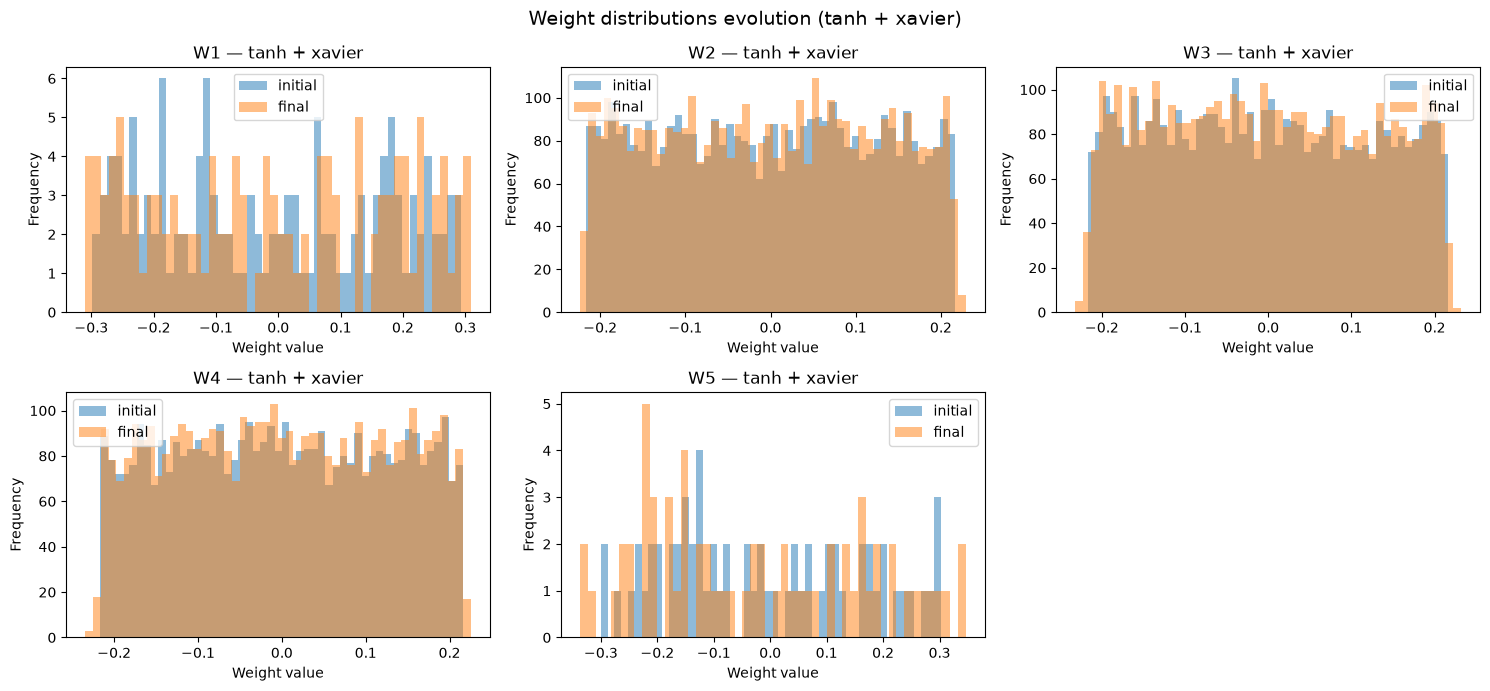

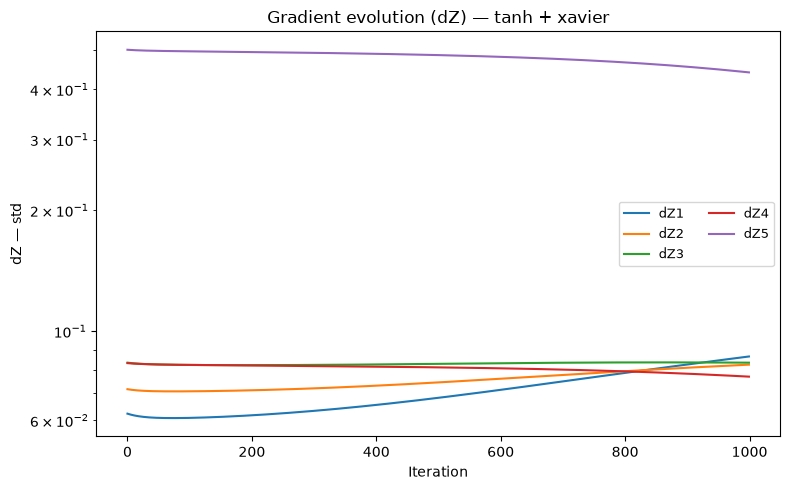

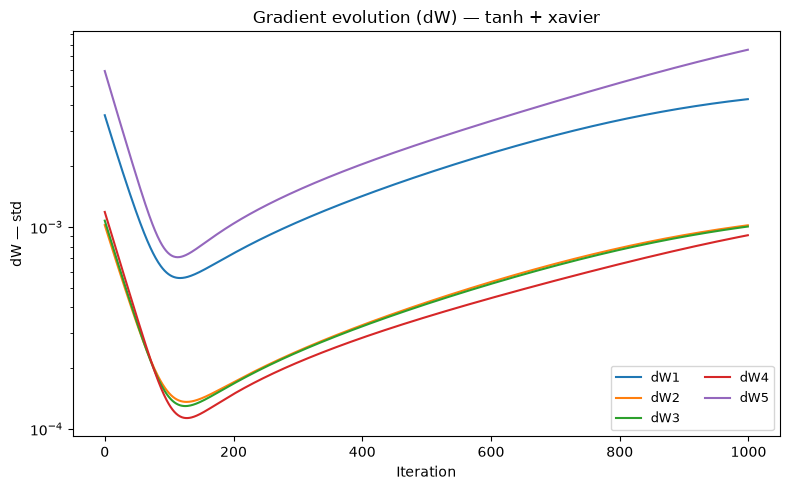

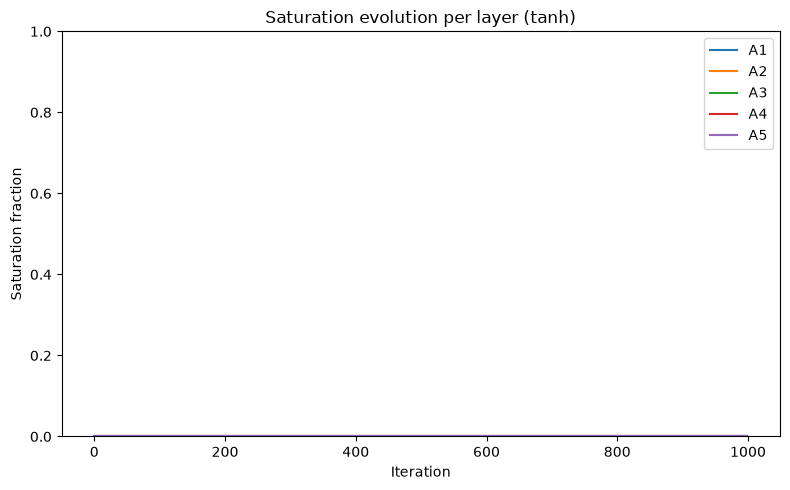

In [35]:
# Exercise 8: Weight evolution interpretation (Selected Example: tanh + xavier)
DATASET = "circles"
X_train, y_train, X_test, y_test = load_dataset_flexible(
    dataset=DATASET,
    random_state=42,
)

layer_dims = [X_train.shape[1], 64, 64, 64, 64, 1]
HIDDEN_ACT = "tanh"
INIT_SCHEME = "xavier"

parameters, losses, grad_hist, initial_params, snapshots, sat_hist = train_deep_model(
    X_train.T,
    y_train,
    layer_dims=layer_dims,
    init_scheme=INIT_SCHEME,
    hidden_activation=HIDDEN_ACT,
    learning_rate=0.01,
    num_iterations=1000,
    print_every=0,
    track_saturation=True,
)

# 1. Weight evolution: Initial vs Final distribution per layer
plot_weights_evolution(initial_params, parameters, activation=f"{HIDDEN_ACT} + {INIT_SCHEME}")

# 2. Gradient evolution across layers
plot_gradients_evolution(grad_hist, activation=f"{HIDDEN_ACT} + {INIT_SCHEME}", metric="std", logy=True)

# 3. Saturation evolution across layers
plot_saturation_evolution(sat_hist, activation=HIDDEN_ACT)


### Answers

1. **How does weight variance correlate with gradient variance:**
   * **Direct correlation visible across the plots:** Because Xavier initialization keeps weight variances balanced (bounded tightly between $[-0.22, +0.22]$), activations stay well-behaved.
   * As shown in the gradient plots, gradients for all layers ($dW_1$ to $dW_5$) stay active, stable, and tightly bundled within $[10^{-4}, 5 \times 10^{-3}]$ without vanishing or exploding. Stable weights preserve the backpropagation signal, keeping gradient variance healthy throughout training.

2. **Which layers drift the most:**
   * **The output layer ($W_5$) drifts the most, followed by the input layer ($W_1$):**
     * In the weight histogram for $W_5$, the final distribution visibly shifts away from the initial spread, forming a peak around $-0.22$ and spreading out to $\pm 0.35$ to fit the binary classification boundary.
     * In contrast, intermediate layers ($W_2, W_3, W_4$) show **almost zero drift**: their final orange histograms overlap almost 100% with the initial blue histograms.
     * This directly matches the gradient plot, where **$dW_5$ and $dW_1$ have the largest gradient magnitudes** in the network, driving the most parameter change.

3. **Does saturation match the behavior of weights:**
   * **Yes, perfectly:**
     * The saturation plot shows that the saturation fraction is **flat at exactly 0.0 (0%) across all layers** for the entire 1000 iterations.
     * This directly reflects the weight histograms: because weights remained compact and never blew up, pre-activations ($Z = WA + b$) stayed inside the linear range of tanh ($|Z| < 1.0$), completely preventing any neurons from saturating.


## **Summary task: Final report**

### **Objective:**

Synthesize all your experimental findings.

### Write a short report answering:

1. Why do gradients vanish or explode in deep networks?
2. Why do poor initializations saturate tanh/sigmoid or kill ReLUs?
3. Why do Xavier and He initialization solve these problems?
4. How do toy 2D experiments compare to real image data?
5. How do gradient evolution, saturation, and weight evolution relate?

# Final Synthesis Report: Initialization, Saturation, and Gradient Dynamics

### 1. Why do gradients vanish or explode in deep networks?
Backpropagation relies on repeated chain-rule multiplication across all $L$ layers:
$$\frac{\partial \mathcal{L}}{\partial W^{[l]}} \propto \prod_{k=l+1}^{L} \left( W^{[k]T} \cdot \sigma'(Z^{[k]}) \right)$$
* **Vanishing Gradients:** If the effective multiplier $(W^T \cdot \sigma')$ is repeatedly less than $1.0$—caused by squashing activation functions ($|\tanh'| \le 1$) or small weights—the gradient signal shrinks exponentially as it travels backward, vanishing to near zero in deep layers and stalling optimization.
* **Exploding Gradients:** Conversely, if weight magnitudes or un-squashed activations have variance significantly greater than $1.0$, the backward signal amplifies exponentially, causing wild parameter oscillations and numerical overflow.

---

### 2. Why do poor initializations saturate tanh/sigmoid or kill ReLUs?
* **Tanh / Sigmoid Saturation:** When initial weights have excessive variance (e.g., $\sigma = 2.0$), pre-activations $Z = \sum W_i X_i + b$ blow up ($|Z| \gg 1$). Tanh squashes large inputs to $\pm 1$, where its derivative flattens to zero ($\tanh'(Z) \approx 0$). This derivative term multiplies incoming gradients during backprop, choking gradient flow.
* **Dying ReLU:** Because $\text{ReLU}(Z) = \max(0, Z)$, its derivative is strictly 0 for $Z \le 0$. Poor initialization or large initial steps easily push neuron pre-activations into negative values for all inputs. Once a neuron outputs $0$ everywhere, its gradient becomes permanently $0$ ($dW = 0$), leaving it permanently dead and unrecoverable.

---

### 3. Why do Xavier and He initialization solve these problems?
Both methods calibrate initial weight variances to maintain constant activation variance across forward layers:
* **Xavier (Glorot) for Tanh/Sigmoid:** Sets $\text{Var}(W) = \frac{2}{\text{fan\_in} + \text{fan\_out}}$. This keeps activations centered in tanh's linear region ($|Z| < 1$, where $\tanh'(Z) \approx 1$), preventing saturation and maintaining unattenuated gradient flow.
* **He (Kaiming) for ReLU:** Sets $\text{Var}(W) = \frac{2}{\text{fan\_in}}$. The factor of $2$ precisely counterbalances the fact that ReLU deactivates half the units on average, preventing signal variance from decaying by $0.5$ per layer.

---

### 4. How do toy 2D experiments compare to real image data?
* **Common principles:** The core mechanics—variance preservation, activation saturation, and backpropagation chain decay—operate identically on both toy and real datasets. Poor initialization halts training in both settings.
* **Key differences:**
  * **Input dimensionality:** Real images have thousands of features ($n_x = 12,288$ for raw $64 \times 64 \times 3$ images) versus $n_x = 2$ for toy circles. Large input dimension accelerates pre-activation explosion unless inputs are normalized and weights are scaled by $1 / \sqrt{n_x}$.
  * **Landscape complexity:** Real image manifolds are far more complex and noisy. While full-batch descent on 2D circles can tolerate aggressive step sizes (e.g., $\alpha = 0.1$), high-dimensional image tasks require tighter stability margins and adaptive optimizers.

---

### 5. How do gradient evolution, saturation, and weight evolution relate?
They form a direct causal cycle:
1. **Weights dictate Saturation:** Large weight magnitudes produce large pre-activations $Z$, pushing neurons into saturation (flattened tanh or negative ReLU).
2. **Saturation dictates Gradients:** High saturation drops local derivatives $\sigma'(Z) \to 0$, which directly attenuates or zeros out backpropagating gradients ($dZ, dW$).
3. **Gradients dictate Weight Evolution:** Gradients determine parameter updates ($\Delta W = -\alpha \cdot dW$). Vanished gradients freeze weights in place (zero drift), while balanced gradients enable steady, stable weight evolution to fit the decision boundary.

When initialization is well-matched (Xavier for tanh, He for ReLU), **saturation stays near 0%**, **gradients remain stable across depth**, and **weights evolve smoothly without exploding or dying**.
